# Tarea 2 · Deep Learning (CIT3360) — Ítem 1: CNN propia entrenada desde cero

> **Variante 80/10/10.** Copia de `../01_cnn_propia_desde_cero.ipynb` que entrena y evalúa con la partición 80/10/10 de esta carpeta (train 2400, val 301 y test 301 imágenes; huella `84ea7ae5b688`). Solo cambian las rutas, la huella y los textos que dependen de la partición: el diseño, los hiperparámetros y las decisiones del grupo son los del original, salvo el NMS de la evaluación: IoU 0,5 en vez de 0,7 (`IOU_NMS`, cambio del 9 de noviembre de 2026; el entrenamiento no se repitió). Los pesos y registros van a `~/tarea2_runs_80_10_10/`.

Detector de objetos con una **arquitectura CNN propia**, entrenado **desde cero** (pesos aleatorios) sobre FjordFish. Es el puerto a PyTorch del diseño que el grupo hizo en TensorFlow (`referencia/CNN_original_tensorflow.ipynb`). Se mantienen la arquitectura, la cabeza de salida, la asignación de cajas y la función de pérdida, salvo los cambios de diseño de D2, y se corrige lo que impedía entrenarlo: imágenes TIFF con extensión `.jpg`, falta de memoria en la GPU, particiones distintas a las de YOLO y falta de evaluación. Se entrena, valida y prueba con las mismas particiones que YOLO desde cero (`02_yolo_desde_cero.ipynb`).

**Ítems de la rúbrica**
- 1.1 (CNN propia entrenada desde cero): secciones 3 a 12.
- 1.2 (mismas particiones que YOLO): sección 2.
- 1.3 (justificación de las decisiones): sección 16.
- 1.4 (comparación con YOLO): `05_comparacion.ipynb`, con los archivos que deja la sección 15.

**Decisiones del grupo que usa este cuaderno**

| | Decisión | Estado |
|---|---|---|
| D1 | Implementación en PyTorch | decidida |
| D2 | Cambios de diseño | decidida: centro de la caja relativo a su celda, BatchNorm y peso del fondo 0,1 (prueba en la sección 9) |
| D3 | Entrada de 640 px con *letterbox*, igual que YOLO | decidida |
| D4 | Épocas, paciencia y criterio de parada | decidida: hasta 100 épocas con paciencia 25 y parada por mAP50-95 de validación, como YOLO |
| D5 | El mismo aumento de datos que YOLO, sin mosaico | decidida |
| D6 | Las 28 categorías de `data.yaml` | decidida |
| D8 | Un mismo umbral de confianza para la precisión y el recall de todos los modelos | pendiente el valor: se elige con validación en `05_comparacion.ipynb` |

**Contenido**
0. Entorno · 1. Configuración · 2. Verificación de las particiones · 3. Datos: letterbox y aumento · 4. Arquitectura · 5. Asignación de cajas a candidatas · 6. Función de pérdida · 7. Decodificación y NMS · 8. Optimizador y ciclo de entrenamiento · 9. Prueba de sobreajuste (D2) · 10. Entrenamiento · 11. Curvas · 12. Evaluación en validación y test · 13. Eficiencia · 14. Resultados cualitativos · 15. Predicciones y resumen para la comparación · 16–17. Justificación y análisis (grupo) · Declaración de uso de IA

### Diseño del detector: qué se mantiene del original y qué cambia

| Aspecto | Cuaderno original (TensorFlow) | Este cuaderno (PyTorch) |
|---|---|---|
| Entrada | Imagen deformada a 640 × 640 | 640 × 640 con *letterbox*, sin deformar (D3) |
| Cuerpo | 13 convoluciones 3×3 con ReLU en 6 bloques (de 32 a 1024 filtros) y 5 *max-pool* de stride 2: grilla de 20 × 20 celdas | Igual, con BatchNorm después de cada convolución (D2) |
| Cabeza | Convolución 1×1: 10 candidatas por celda (4000 por imagen), cada una con 4 valores de caja (cx, cy, w, h respecto de toda la imagen) y 29 puntajes de clase (28 clases + fondo) | Igual, pero el centro de la caja se predice relativo a su celda y el ancho y alto con sigmoide (D2) |
| Asignación | Cada caja real va a la celda que contiene su centro y toma la candidata libre con mayor IoU respecto de lo que esa candidata predice | Igual |
| Pérdida | Error cuadrático de caja + entropía cruzada de clase (el fondo pesa 1/4000), normalizados por las candidatas asignadas; L2 en los kernels | Igual, pero el fondo pesa 0,1 y cada candidata parte con probabilidad de objeto 0,01 (D2); la entropía cruzada se calcula desde los logits |
| Entrenamiento | SGD (momentum 0,9, lr 1e-3), micro-lotes de 3 imágenes con acumulación de gradientes (lote efectivo de 15) y parada temprana sobre la pérdida de validación | Igual, con precisión mixta como YOLO; hasta 100 épocas, paciencia 25 y parada por mAP50-95 de validación (D4) |
| Aumento de datos | Ninguno | El mismo que YOLO desde cero, sin mosaico (D5) |
| Particiones y evaluación | Train y val originales, sin test ni mAP | Las particiones comunes y el evaluador común de `comun.py` |

## 0. Entorno

Requiere PyTorch con CUDA, torchvision y OpenCV (ver `requirements.txt`) y `comun.py` en la misma carpeta. El detector, la asignación, la pérdida y el entrenamiento están escritos en este cuaderno; no usa Ultralytics.

In [1]:
import json
import logging
import math
import os
import random
import time
import platform
import warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")   # cuBLAS determinista, como YOLO; debe ir antes de usar CUDA
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import torch
import torch.nn as nn
import torch.nn.functional as F
import yaml
from PIL import Image
from torchvision.ops import batched_nms

logging.getLogger("torch.utils.flop_counter").setLevel(logging.ERROR)   # oculta un aviso sobre triton que aquí no aplica
from torch.utils.flop_counter import FlopCounterMode

from comun import (cargar_particiones, verificar_huella, leer_etiquetas_yolo, cargar_cajas_reales, evaluar_detecciones,
                   COLUMNAS_PREDICCIONES, CARPETA_RUNS)

warnings.filterwarnings("ignore", message=".*does not have a deterministic implementation.*")   # ver la sección 8

print("Python  :", platform.python_version())
print("PyTorch :", torch.__version__, "| CUDA disponible:", torch.cuda.is_available())
print("OpenCV  :", cv2.__version__)
if torch.cuda.is_available():
    print("GPU     :", torch.cuda.get_device_name(0))
DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cv2.setNumThreads(1)   # la carga en paralelo la hacen los hilos de `lotes`; así OpenCV no compite con ellos

Python  : 3.14.0
PyTorch : 2.14.0+cu130 | CUDA disponible: True
OpenCV  : 5.0.0
GPU     : NVIDIA GeForce RTX 4060 Laptop GPU


In [2]:
# Estilo de los gráficos: colores categóricos en orden fijo (azul, naranja, aqua) y ejes discretos
AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#898781"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False, "figure.dpi": 100,
})

## 1. Configuración

Todos los valores numéricos están en esta celda; la arquitectura (sección 4) y las variantes de la prueba de sobreajuste (sección 9) se definen en sus secciones. Los valores del detector y del entrenamiento son los del cuaderno original del grupo; los marcados con **D2** o **D4** son decisiones del grupo.

| Parámetro | Qué controla |
|---|---|
| `PRUEBA_RAPIDA`, `ENTRENAR`, `PROBAR_SOBREAJUSTE` | prueba rápida; entrenar o reutilizar el entrenamiento guardado; repetir la prueba de sobreajuste o mostrar la guardada |
| `LADO`, `GRILLA` | lado de la imagen de entrada (px) y celdas por lado de la grilla de salida (`LADO / 32`) |
| `N_CANDIDATAS` | candidatas por celda |
| `COORDENADAS_RELATIVAS`, `USAR_BATCHNORM` | **D2**: cambios de diseño que evalúa la prueba de sobreajuste (`False` = como el original) |
| `PESO_CAJA`, `PESO_CLASE`, `PESO_FONDO`, `LAMBDA_L2` | pesos de la pérdida y regularización L2; `PESO_FONDO` es **D2** (1/4000 en el original) |
| `PROB_OBJETO_INICIAL` | **D2**: probabilidad de objeto con que parte cada candidata |
| `EPOCAS`, `PACIENCIA`, `CRITERIO_PARADA` | **D4**: máximo de épocas y parada temprana (`"perdida_val"` como el original o `"mAP50_95_val"` como YOLO) |
| `TASA_APRENDIZAJE`, `MOMENTUM` | SGD con momentum |
| `MICRO_LOTE`, `ACUMULAR` | imágenes por paso y pasos acumulados por actualización (lote efectivo = producto) |
| `PRECISION_MIXTA` | float16 en la GPU para entrenar y para la validación de cada época, como YOLO; la evaluación final y la velocidad se miden en float32, también como YOLO |
| `HILOS_CARGA`, `LOTE_EVALUACION` | hilos que preparan las imágenes e imágenes por paso al evaluar (no cambian los resultados) |
| `ESCALA`, `TRASLACION`, `HSV_H`, `HSV_S`, `HSV_V`, `VOLTEO`, `COLOR_RELLENO` | aumento de datos y letterbox: los mismos valores que YOLO desde cero (D5) |
| `CONF_EVALUACION`, `IOU_NMS`, `MAX_DETECCIONES`, `MAX_ANTES_NMS` | detecciones que se guardan para el mAP (los mismos valores que YOLO) |
| `UMBRAL_CONFIANZA` | confianza mínima de las detecciones que se dibujan y de la precisión y el recall de este cuaderno (umbral común que fijó el grupo, D8) |
| `IMAGENES_SOBREAJUSTE`, `EPOCAS_SOBREAJUSTE` | tamaño de la prueba de sobreajuste |
| `N_IMAGENES_VELOCIDAD`, `N_EJEMPLOS` | imágenes para medir la velocidad y para los ejemplos cualitativos |

Con `PRUEBA_RAPIDA = True` el cuaderno corre en unos minutos (2 épocas con el 5 % de train y 3 épocas de prueba de sobreajuste) y escribe en `pruebas/`, sin pisar los resultados reales. Con `ENTRENAR = False` se reutiliza el entrenamiento guardado, y con `PROBAR_SOBREAJUSTE = False` se muestra la prueba de sobreajuste guardada.

Los pesos y registros del entrenamiento se guardan en `~/tarea2_runs_80_10_10/` (`CARPETA_RUNS` de `comun.py`), fuera de OneDrive: la sincronización bloquea los archivos que se reescriben en cada época y detiene el entrenamiento. Las tablas y figuras van en `resultados/cnn_propia/`, dentro del proyecto.

In [3]:
RAIZ = Path.cwd()
PRUEBA_RAPIDA = False       # True: pocas imágenes y épocas para probar el flujo completo en minutos
ENTRENAR = False            # False: reutiliza el entrenamiento guardado en DIR_RUNS
PROBAR_SOBREAJUSTE = False  # en esta variante queda en False: se muestra la prueba guardada del cuaderno original

DIR_DATASET = RAIZ / "datasets" / "fjordfish"
DIR_SPLITS = RAIZ / "splits"
DIR_ORIGINAL = RAIZ.parent        # carpeta principal: la partición original y las pruebas de diseño guardadas
DIR_BASE = RAIZ / "pruebas" if PRUEBA_RAPIDA else RAIZ      # las pruebas no pisan los resultados reales
DIR_RUNS = CARPETA_RUNS / ("pruebas" if PRUEBA_RAPIDA else "reales") / "cnn_propia"   # pesos y registros, fuera de OneDrive
DIR_RESULTADOS = DIR_BASE / "resultados" / "cnn_propia"      # tablas y figuras para la presentación
SEMILLA = 42

# Detector (diseño del cuaderno original)
LADO = 640                         # entrada de LADO × LADO px con letterbox (D3)
GRILLA = LADO // 32                # 5 max-pool de stride 2 => stride total 32 => grilla de 20 × 20 celdas
N_CANDIDATAS = 10                  # candidatas por celda
NUM_CLASES = 28                    # clases 0..27 de data.yaml (D6)
FONDO = NUM_CLASES                 # índice de la clase "fondo" (28)
SALIDAS_POR_CANDIDATA = 4 + NUM_CLASES + 1    # 4 de caja + 29 de clase = 33
COORDENADAS_RELATIVAS = True       # D2 (decidido por el grupo): centro de la caja relativo a su celda
USAR_BATCHNORM = True              # D2 (decidido por el grupo): BatchNorm después de cada convolución

# Pérdida (cuaderno original, salvo D2)
PESO_CAJA = 3.0
PESO_CLASE = 1.0
PESO_FONDO = 0.1                   # D2 (decidido por el grupo): peso de cada candidata de fondo (el original usó 1/4000)
PROB_OBJETO_INICIAL = 0.01         # D2: probabilidad de objeto con que parte cada candidata
LAMBDA_L2 = 1e-4                   # regularización L2 de los kernels: LAMBDA_L2 · Σ w²

# Entrenamiento (cuaderno original, salvo D4)
EPOCAS = 100                       # D4 (decidido por el grupo)
PACIENCIA = 25                     # D4 (decidido por el grupo)
CRITERIO_PARADA = "mAP50_95_val"   # D4 (decidido por el grupo): como YOLO; "perdida_val" era el del original
TASA_APRENDIZAJE = 1e-3
MOMENTUM = 0.9
MICRO_LOTE = 3                     # imágenes por paso (el original estaba limitado por una GPU de 2 GB)
ACUMULAR = 5                       # micro-lotes por actualización de pesos: lote efectivo de 15 imágenes
PRECISION_MIXTA = True             # float16 en la GPU, como YOLO (AMP)
USAR_AMP = PRECISION_MIXTA and DISPOSITIVO.type == "cuda"
HILOS_CARGA = 8                    # hilos que leen y aumentan imágenes en paralelo
LOTE_EVALUACION = 16               # imágenes por paso al evaluar (no cambia los resultados)

# Aumento de datos y letterbox: los mismos valores que YOLO desde cero, sin mosaico (D5)
ESCALA = 0.5                       # factor de escala al azar en [1 − ESCALA, 1 + ESCALA]
TRASLACION = 0.1                   # desplazamiento al azar del centro: hasta ±10 % del lado
HSV_H, HSV_S, HSV_V = 0.015, 0.7, 0.4    # variación máxima de tono, saturación y brillo
VOLTEO = 0.5                       # probabilidad de volteo horizontal
COLOR_RELLENO = 114                # gris del letterbox (el mismo de Ultralytics)

# Evaluación (los mismos valores que YOLO)
CONF_EVALUACION = 0.001            # confianza mínima de las detecciones que se guardan para el mAP
IOU_NMS = 0.5
MAX_DETECCIONES = 300              # por imagen (el mismo límite que aplica comun.py)
MAX_ANTES_NMS = 30_000             # detecciones que entran al NMS por imagen (el mismo límite de Ultralytics)
UMBRAL_CONFIANZA = 0.25            # D8: umbral común que fijó el grupo con validación

# Prueba de sobreajuste (D2), velocidad y ejemplos
IMAGENES_SOBREAJUSTE = 16
EPOCAS_SOBREAJUSTE = 300
N_IMAGENES_VELOCIDAD = 200
N_EJEMPLOS = 4

FRACCION_TRAIN = 1.0               # parte de train que se usa (solo se reduce en la prueba rápida)
if PRUEBA_RAPIDA:
    EPOCAS = 2
    PACIENCIA = 2
    EPOCAS_SOBREAJUSTE = 3
    FRACCION_TRAIN = 0.05

assert CRITERIO_PARADA in ("perdida_val", "mAP50_95_val"), "CRITERIO_PARADA debe ser 'perdida_val' o 'mAP50_95_val'"
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
DIR_RUNS.mkdir(parents=True, exist_ok=True)
DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)
print(f"Grilla {GRILLA} × {GRILLA} | {GRILLA * GRILLA * N_CANDIDATAS} candidatas por imagen "
      f"| lote efectivo de {MICRO_LOTE * ACUMULAR} imágenes")

Grilla 20 × 20 | 4000 candidatas por imagen | lote efectivo de 15 imágenes


Funciones para dibujar que se usan en varias secciones: un lienzo de la red con sus cajas normalizadas, una imagen con cajas en píxeles (reales o predichas) y un eje de épocas con números enteros.

In [4]:
def dibujar_lienzo(ax, imagen, objetivos, titulo):
    """Muestra un lienzo de LADO × LADO con sus cajas (objetivos normalizados: clase, cx, cy, w, h)."""
    ax.imshow(imagen.permute(1, 2, 0).numpy())
    for _, cx, cy, w, h in objetivos.tolist():
        ax.add_patch(plt.Rectangle(((cx - w / 2) * LADO, (cy - h / 2) * LADO), w * LADO, h * LADO,
                                   fill=False, ec=NARANJA, lw=1.5))
    ax.set_title(titulo, fontsize=9)
    ax.axis("off")


def dibujar_cajas(ax, img, cajas, titulo):
    """Muestra una imagen con sus cajas en píxeles (tabla con clase_id, x1, y1, x2, y2 y, si la hay, confianza)."""
    ax.imshow(img)
    for fila in cajas.itertuples():
        ax.add_patch(plt.Rectangle((fila.x1, fila.y1), fila.x2 - fila.x1, fila.y2 - fila.y1,
                                   fill=False, ec=NARANJA, lw=1.5))
        texto = NOMBRES[fila.clase_id] + (f" {fila.confianza:.2f}" if hasattr(fila, "confianza") else "")
        ax.text(fila.x1, fila.y1, texto, color="white", fontsize=7, va="top" if fila.y1 < 0.05 * img.height else "bottom",
                bbox=dict(fc=NARANJA, ec="none", pad=1), clip_on=True)
    ax.set_title(titulo, fontsize=9)
    ax.axis("off")


def epocas_enteras(ax):
    """Deja solo números enteros en el eje de las épocas."""
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))

## 2. Verificación del dataset y de las particiones

Se comprueba que las carpetas del dataset coinciden con `splits/*.txt` y que la **huella** de las particiones es la común del grupo (`84ea7ae5b688`, la misma que verifica `02_yolo_desde_cero.ipynb`). Si no coincide, el cuaderno se detiene: así se garantiza que la CNN y YOLO usan las mismas particiones (ítem 1.2).

In [5]:
assert (DIR_DATASET / "fjordfish.yaml").exists(), "Primero hay que ejecutar 00_preparacion_dataset.ipynb"
datos = yaml.safe_load((DIR_DATASET / "fjordfish.yaml").read_text(encoding="utf-8"))
NOMBRES = datos["names"]
assert len(NOMBRES) == NUM_CLASES, "NUM_CLASES no coincide con data.yaml"
particion, huella = cargar_particiones(DIR_SPLITS)
verificar_huella(huella)

filas = []
for s, ids in particion.items():
    en_disco = {p.stem for p in (DIR_DATASET / "images" / s).glob("*.jpg")}
    assert en_disco == set(ids), f"images/{s} no coincide con splits/{s}.txt"
    n_cajas = sum(len(leer_etiquetas_yolo(DIR_DATASET / "labels" / s / f"{i}.txt")) for i in ids)
    filas.append({"partición": s, "imágenes": len(ids), "cajas": n_cajas})
print(f"{NUM_CLASES} clases | huella de la partición: {huella} (verificada)")
pd.DataFrame(filas).set_index("partición")

28 clases | huella de la partición: 84ea7ae5b688 (verificada)


,imágenes,cajas
partición,,
train,2400,5076
val,301,622
test,301,649


## 3. Datos: letterbox y aumento de datos

Cada imagen se prepara igual que en YOLO (D3 y D5), en este orden:
1. Se cambia de tamaño para que su lado mayor mida `LADO` px, sin deformarla.
2. Se ubica en un lienzo gris de `LADO` × `LADO` (*letterbox*). En entrenamiento, además, se escala al azar entre 0,5× y 1,5× y su centro se desplaza hasta ±10 %; se descartan las cajas que quedan con menos del 10 % de su área o con un lado de 2 px o menos (el mismo criterio de Ultralytics).
3. Solo en entrenamiento: cambios de tono, saturación y brillo (HSV), que también afectan al relleno gris, y volteo horizontal con probabilidad 0,5.

Las cajas quedan como `clase, cx, cy, w, h`, normalizadas respecto del lienzo. En validación y test solo se aplica el letterbox centrado, y se guarda cómo deshacerlo para devolver las predicciones a píxeles de la imagen de `datasets/fjordfish/`.

Las imágenes se preparan en varios hilos en paralelo mientras la GPU procesa el lote anterior. Se usan hilos y no el `DataLoader` de PyTorch con procesos porque en Windows esos procesos no pueden usar clases definidas dentro de un cuaderno.

In [6]:
def cxcywh_a_xyxy(cajas):
    """Cajas (cx, cy, w, h) → (x1, y1, x2, y2), en las mismas unidades."""
    cx, cy, w, h = np.asarray(cajas, dtype=np.float64).reshape(-1, 4).T
    return np.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], axis=1)


def xyxy_a_cxcywh(cajas):
    """Cajas (x1, y1, x2, y2) → (cx, cy, w, h), en las mismas unidades."""
    x1, y1, x2, y2 = np.asarray(cajas, dtype=np.float64).reshape(-1, 4).T
    return np.stack([(x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1], axis=1)


def redimensionar(img):
    """Cambia el tamaño de la imagen para que su lado mayor mida LADO px, sin deformarla (como Ultralytics)."""
    alto, ancho = img.shape[:2]
    r = LADO / max(alto, ancho)
    tamano = (min(math.ceil(ancho * r), LADO), min(math.ceil(alto * r), LADO))
    return cv2.resize(img, tamano, interpolation=cv2.INTER_LINEAR)


def ubicar_en_lienzo(img, cajas, rng=None):
    """Letterbox: ubica la imagen en un lienzo gris de LADO × LADO; con `rng`, además la escala y la desplaza al azar."""
    # Devuelve el lienzo, las cajas que se conservan (px del lienzo), cuáles se conservan y (escala, dx, dy)
    alto, ancho = img.shape[:2]
    escala, centro_x, centro_y = 1.0, LADO / 2, LADO / 2
    if rng is not None:
        escala = rng.uniform(1 - ESCALA, 1 + ESCALA)
        centro_x, centro_y = rng.uniform(0.5 - TRASLACION, 0.5 + TRASLACION, size=2) * LADO
    dx, dy = centro_x - escala * ancho / 2, centro_y - escala * alto / 2   # la imagen queda centrada en (centro_x, centro_y)
    if rng is None:   # letterbox centrado con desplazamiento entero, como Ultralytics (sin interpolar medio píxel)
        dx, dy = round(dx - 0.1), round(dy - 0.1)
    matriz = np.array([[escala, 0, dx], [0, escala, dy]], dtype=np.float32)
    lienzo = cv2.warpAffine(img, matriz, (LADO, LADO), borderValue=(COLOR_RELLENO,) * 3)
    nuevas = (cajas * escala + [dx, dy, dx, dy]).clip(0, LADO)
    conservar = np.ones(len(cajas), dtype=bool)
    if rng is not None:   # mismo criterio que Ultralytics: lado > 2 px, al menos 10 % del área y proporción < 100
        ancho_antes, alto_antes = (cajas[:, 2] - cajas[:, 0]) * escala, (cajas[:, 3] - cajas[:, 1]) * escala
        ancho_ahora, alto_ahora = nuevas[:, 2] - nuevas[:, 0], nuevas[:, 3] - nuevas[:, 1]
        proporcion = np.maximum(ancho_ahora / (alto_ahora + 1e-16), alto_ahora / (ancho_ahora + 1e-16))
        conservar = ((ancho_ahora > 2) & (alto_ahora > 2) & (proporcion < 100)
                     & (ancho_ahora * alto_ahora / (ancho_antes * alto_antes + 1e-16) > 0.1))
    return lienzo, nuevas[conservar], conservar, (escala, dx, dy)


def variar_hsv(img, rng):
    """Cambia al azar el tono, la saturación y el brillo con las mismas tablas que Ultralytics (RandomHSV)."""
    r = rng.uniform(-1, 1, size=3) * [HSV_H, HSV_S, HSV_V]
    x = np.arange(256, dtype=np.float64)
    tono = ((x + r[0] * 180) % 180).astype(np.uint8)              # en OpenCV el tono va de 0 a 179
    saturacion = np.clip(x * (r[1] + 1), 0, 255).astype(np.uint8)
    brillo = np.clip(x * (r[2] + 1), 0, 255).astype(np.uint8)
    saturacion[0] = 0                                             # como Ultralytics: un gris o un blanco sigue sin color
    tabla = np.stack((tono, saturacion, brillo), axis=-1).reshape(1, 256, 3)
    return cv2.cvtColor(cv2.LUT(cv2.cvtColor(img, cv2.COLOR_BGR2HSV), tabla), cv2.COLOR_HSV2BGR)

El `Dataset` aplica esos pasos a cada imagen y entrega la imagen, sus cajas y los datos para deshacer el letterbox. La semilla del aumento depende de la imagen y de la época, así que cada época ve variantes nuevas y el resultado es reproducible.

In [7]:
class DatasetFjordFish(torch.utils.data.Dataset):
    """Imágenes y cajas de una partición, preparadas como en YOLO: letterbox y, si `aumentar`, aumento de datos."""

    def __init__(self, split, ids, aumentar):
        self.split, self.ids, self.aumentar = split, list(ids), aumentar
        self.epoca = 0                  # forma parte de la semilla del aumento: cada época ve variantes nuevas

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        """Devuelve la imagen (3 × LADO × LADO, uint8, RGB), sus objetivos (n, 5) y los datos para deshacer el letterbox."""
        id_img = self.ids[i]
        original = cv2.imread(str(DIR_DATASET / "images" / self.split / f"{id_img}.jpg"))     # BGR
        img = redimensionar(original)
        alto, ancho = img.shape[:2]
        etiquetas = leer_etiquetas_yolo(DIR_DATASET / "labels" / self.split / f"{id_img}.txt")
        cajas = cxcywh_a_xyxy(etiquetas[:, 1:]) * [ancho, alto, ancho, alto]
        rng = np.random.default_rng([SEMILLA, self.epoca, i]) if self.aumentar else None
        lienzo, cajas, conservar, (escala, dx, dy) = ubicar_en_lienzo(img, cajas, rng)
        clases = etiquetas[conservar, 0]
        if self.aumentar:
            lienzo = variar_hsv(lienzo, rng)
            if rng.random() < VOLTEO:
                lienzo = lienzo[:, ::-1]
                cajas[:, [0, 2]] = LADO - cajas[:, [2, 0]]          # al voltear, x1 nuevo = LADO − x2 y x2 nuevo = LADO − x1
        imagen = torch.from_numpy(np.ascontiguousarray(lienzo[..., ::-1].transpose(2, 0, 1)))   # BGR → RGB
        objetivos = torch.from_numpy(np.column_stack([clases, xyxy_a_cxcywh(cajas) / LADO]).astype(np.float32))
        # Para volver a px de la imagen original: x = (x_lienzo − dx) · factor_x  (y lo mismo en y)
        datos_letterbox = {"id": id_img, "ancho": original.shape[1], "alto": original.shape[0], "dx": dx, "dy": dy,
                           "factor_x": original.shape[1] / (ancho * escala), "factor_y": original.shape[0] / (alto * escala)}
        return imagen, objetivos, datos_letterbox

`lotes` recorre un dataset por lotes: las imágenes de cada lote se preparan en `HILOS_CARGA` hilos (OpenCV libera el GIL, así que trabajan en paralelo) y el lote siguiente se va preparando mientras la GPU procesa el actual.

In [8]:
def juntar(muestras):
    """Arma un lote: imágenes (B, 3, LADO, LADO), lista de objetivos por imagen y lista de datos del letterbox."""
    imagenes, objetivos, datos_letterbox = zip(*muestras)
    return torch.stack(imagenes), list(objetivos), list(datos_letterbox)


def lotes(dataset, tamano, mezclar=False):
    """Recorre el dataset en lotes de `tamano` imágenes, preparando el lote siguiente mientras se usa el actual."""
    indices = list(range(len(dataset)))
    if mezclar:
        random.shuffle(indices)
    grupos = [indices[i:i + tamano] for i in range(0, len(indices), tamano)]
    with ThreadPoolExecutor(HILOS_CARGA) as hilos, ThreadPoolExecutor(1) as anticipo:
        def preparar(grupo):
            return juntar(list(hilos.map(dataset.__getitem__, grupo)))

        siguiente = anticipo.submit(preparar, grupos[0]) if grupos else None
        for k in range(len(grupos)):
            lote = siguiente.result()
            if k + 1 < len(grupos):
                siguiente = anticipo.submit(preparar, grupos[k + 1])
            yield lote

Se crean los datasets de las tres particiones: solo train lleva aumento de datos. `FRACCION_TRAIN` reduce train únicamente en la prueba rápida.

In [9]:
ids_train = particion["train"]
if FRACCION_TRAIN < 1:                    # solo en la prueba rápida
    ids_train = sorted(random.Random(SEMILLA).sample(ids_train, max(1, round(len(ids_train) * FRACCION_TRAIN))))
datos_train = DatasetFjordFish("train", ids_train, aumentar=True)
datos_val = DatasetFjordFish("val", particion["val"], aumentar=False)
datos_test = DatasetFjordFish("test", particion["test"], aumentar=False)
rutas_test = sorted((DIR_DATASET / "images" / "test").glob("*.jpg"))   # para medir la velocidad y para los ejemplos
print(f"Imágenes · train: {len(datos_train)} | val: {len(datos_val)} | test: {len(datos_test)}")

Imágenes · train: 2400 | val: 301 | test: 301


Las mismas cuatro imágenes de train sin aumento (arriba, como se ven validación y test) y con aumento (abajo).

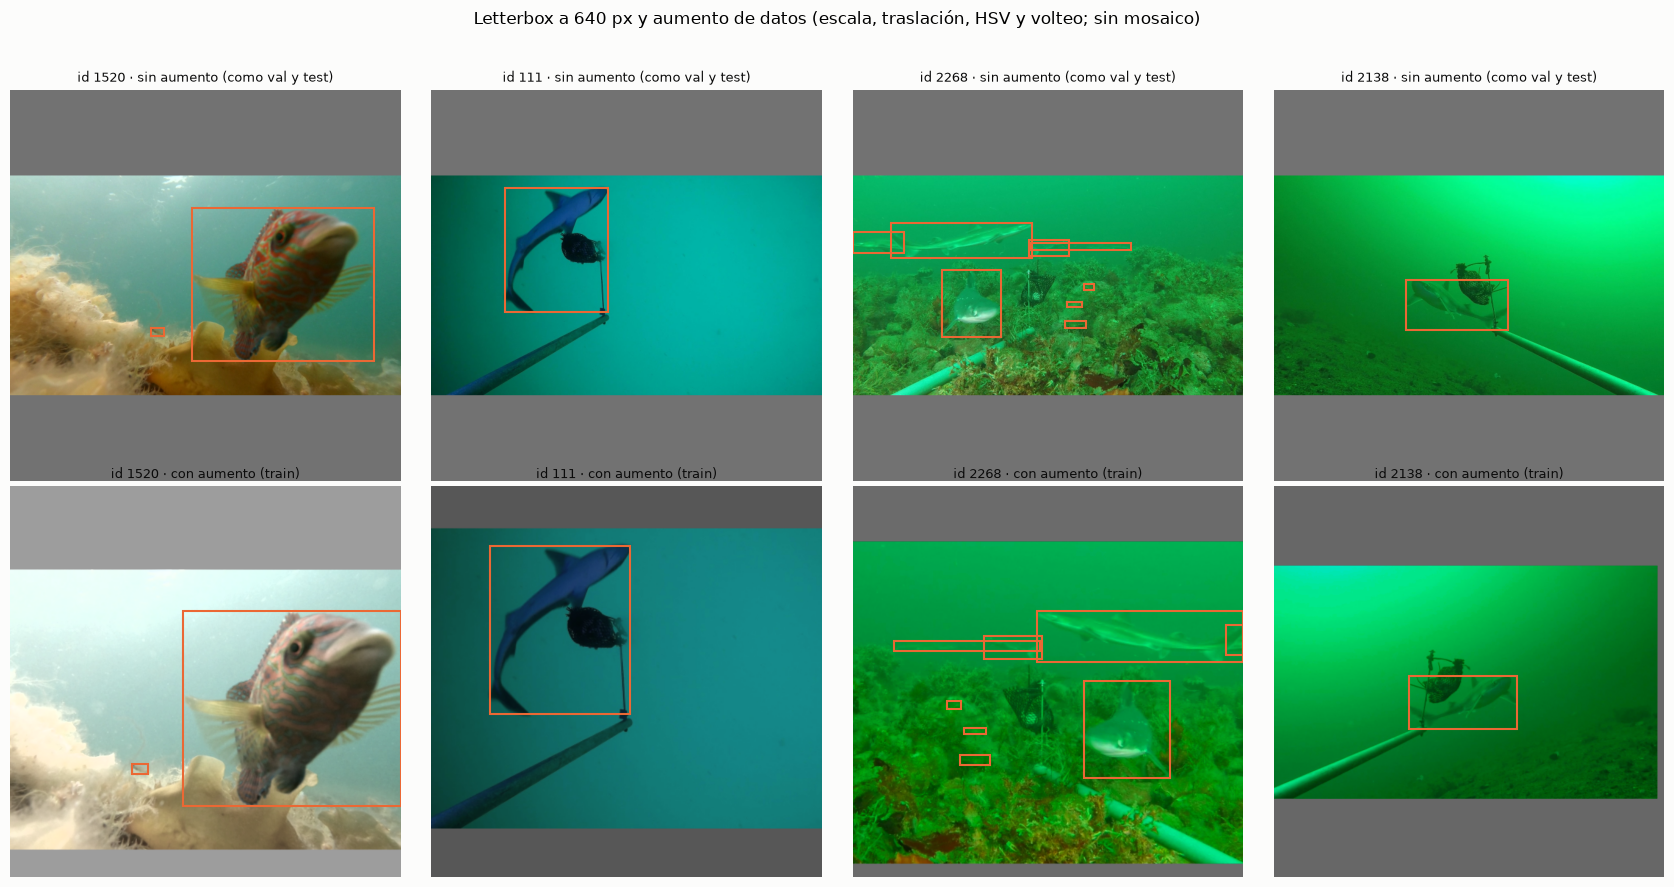

In [10]:
ids_ejemplo = random.Random(SEMILLA).sample(particion["train"], 4)
sin_aumento = DatasetFjordFish("train", ids_ejemplo, aumentar=False)
con_aumento = DatasetFjordFish("train", ids_ejemplo, aumentar=True)
fig, axes = plt.subplots(2, 4, figsize=(17, 9))
for k in range(4):
    imagen, objetivos, letterbox = sin_aumento[k]
    dibujar_lienzo(axes[0, k], imagen, objetivos, f"id {letterbox['id']} · sin aumento (como val y test)")
    imagen, objetivos, letterbox = con_aumento[k]
    dibujar_lienzo(axes[1, k], imagen, objetivos, f"id {letterbox['id']} · con aumento (train)")
fig.suptitle("Letterbox a 640 px y aumento de datos (escala, traslación, HSV y volteo; sin mosaico)", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(DIR_RESULTADOS / "aumento_de_datos.png", dpi=120, bbox_inches="tight")
plt.show()

## 4. Arquitectura

La misma red del cuaderno original, descrita como una lista de capas:
- **Cuerpo:** 6 bloques con 13 convoluciones 3×3 en total (padding 1 y ReLU), de 32, 64, 128, 256, 512 y 1024 filtros. Los cinco primeros bloques terminan en un *max-pool* 2×2 de stride 2, así que la imagen de 640 px queda en una grilla de 20 × 20 celdas.
- **Cabeza:** una convolución 1×1 que entrega, en cada celda, `N_CANDIDATAS` × 33 valores: 4 de caja y 29 puntajes de clase (28 clases + fondo).
- **Inicialización:** Glorot uniforme y sesgos en 0, la misma que usaba Keras en el original. La excepción es el sesgo de la salida de fondo de la cabeza, que hace que cada candidata parta con probabilidad de objeto `PROB_OBJETO_INICIAL` (D2).

Las dos opciones de D2 se activan en la configuración: `USAR_BATCHNORM` agrega BatchNorm después de cada convolución, y `COORDENADAS_RELATIVAS` cambia cómo se leen los 4 valores de caja (método `cajas`). Sin BatchNorm, la red tiene los mismos parámetros que el original.

In [11]:
ARQUITECTURA = [
    # Bloque 1 (640 → 320)
    {"tipo": "conv", "filtros": 32}, {"tipo": "conv", "filtros": 32}, {"tipo": "maxpool"},
    # Bloque 2 (320 → 160)
    {"tipo": "conv", "filtros": 64}, {"tipo": "conv", "filtros": 64}, {"tipo": "maxpool"},
    # Bloque 3 (160 → 80)
    {"tipo": "conv", "filtros": 128}, {"tipo": "conv", "filtros": 128}, {"tipo": "maxpool"},
    # Bloque 4 (80 → 40)
    {"tipo": "conv", "filtros": 256}, {"tipo": "conv", "filtros": 256}, {"tipo": "maxpool"},
    # Bloque 5 (40 → 20)
    {"tipo": "conv", "filtros": 512}, {"tipo": "conv", "filtros": 512}, {"tipo": "maxpool"},
    # Bloque 6 (20 × 20)
    {"tipo": "conv", "filtros": 1024}, {"tipo": "conv", "filtros": 1024}, {"tipo": "conv", "filtros": 1024},
]


class DetectorCNN(nn.Module):
    """Cuerpo convolucional del cuaderno original y cabeza 1×1 con N_CANDIDATAS candidatas por celda."""

    def __init__(self, arquitectura, coordenadas_relativas=False, usar_batchnorm=False,
                 peso_fondo=PESO_FONDO, prob_objeto_inicial=PROB_OBJETO_INICIAL):
        super().__init__()
        self.coordenadas_relativas = coordenadas_relativas
        self.peso_fondo = peso_fondo             # lo usa la pérdida (sección 6)
        capas, canales = [], 3
        for capa in arquitectura:
            if capa["tipo"] == "maxpool":
                capas.append(nn.MaxPool2d(kernel_size=2, stride=2))
                continue
            # con BatchNorm el sesgo de la convolución sobra: BatchNorm ya tiene el suyo
            capas.append(nn.Conv2d(canales, capa["filtros"], kernel_size=3, padding=1, bias=not usar_batchnorm))
            if usar_batchnorm:
                capas.append(nn.BatchNorm2d(capa["filtros"]))
            capas.append(nn.ReLU(inplace=True))
            canales = capa["filtros"]
        self.cuerpo = nn.Sequential(*capas)
        self.cabeza = nn.Conv2d(canales, N_CANDIDATAS * SALIDAS_POR_CANDIDATA, kernel_size=1)
        for m in self.modules():                 # la misma inicialización que usaba Keras en el original
            if isinstance(m, nn.Conv2d):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
        if prob_objeto_inicial is not None:      # None: las 29 clases parten equiprobables, como el original
            sesgo_fondo = math.log((1 - prob_objeto_inicial) / (prob_objeto_inicial / NUM_CLASES))
            with torch.no_grad():
                self.cabeza.bias[4 + FONDO::SALIDAS_POR_CANDIDATA] = sesgo_fondo

    def forward(self, x):
        """Imágenes (B, 3, LADO, LADO) en [0, 1] → salida cruda (B, GRILLA, GRILLA, N_CANDIDATAS, 33)."""
        y = self.cabeza(self.cuerpo(x))                                    # (B, N_CANDIDATAS · 33, GRILLA, GRILLA)
        return y.permute(0, 2, 3, 1).reshape(len(x), GRILLA, GRILLA, N_CANDIDATAS, SALIDAS_POR_CANDIDATA)

    def cajas(self, salida):
        """Cajas (cx, cy, w, h) normalizadas respecto del lienzo, a partir de los 4 primeros valores (D2)."""
        crudas = salida[..., :4]
        if not self.coordenadas_relativas:
            return crudas                                                  # el original: valores sin activación
        fila = torch.arange(GRILLA, device=salida.device).view(1, GRILLA, 1, 1)
        columna = torch.arange(GRILLA, device=salida.device).view(1, 1, GRILLA, 1)
        cx = (torch.sigmoid(crudas[..., 0]) + columna) / GRILLA            # desplazamiento dentro de su celda
        cy = (torch.sigmoid(crudas[..., 1]) + fila) / GRILLA
        return torch.stack([cx, cy, torch.sigmoid(crudas[..., 2]), torch.sigmoid(crudas[..., 3])], dim=-1)

La celda siguiente construye la red con la configuración (todavía sin entrenar) y muestra cada capa con el tamaño de su salida y su número de parámetros.

In [12]:
modelo_inicial = DetectorCNN(ARQUITECTURA, COORDENADAS_RELATIVAS, USAR_BATCHNORM).to(DISPOSITIVO).eval()
filas, x = [], torch.zeros(1, 3, LADO, LADO, device=DISPOSITIVO)
with torch.no_grad():
    for capa in [*modelo_inicial.cuerpo, modelo_inicial.cabeza]:
        x = capa(x)
        if not isinstance(capa, nn.ReLU):
            filas.append({"capa": type(capa).__name__, "salida (canales × alto × ancho)": " × ".join(map(str, x.shape[1:])),
                          "parámetros": sum(p.numel() for p in capa.parameters())})
pd.DataFrame(filas)

,capa,salida (canales × alto × ancho),parámetros
0,Conv2d,32 × 640 × 640,864
1,BatchNorm2d,32 × 640 × 640,64
2,Conv2d,32 × 640 × 640,9216
3,BatchNorm2d,32 × 640 × 640,64
4,MaxPool2d,32 × 320 × 320,0
5,Conv2d,64 × 320 × 320,18432
6,BatchNorm2d,64 × 320 × 320,128
7,Conv2d,64 × 320 × 320,36864
8,BatchNorm2d,64 × 320 × 320,128
9,MaxPool2d,64 × 160 × 160,0


Se verifica la forma de la salida y se cuentan los parámetros y los GFLOPs de una pasada con una imagen de 640 × 640 (2 FLOPs por multiplicación-suma, la misma convención que Ultralytics usa para YOLO).

In [13]:
def tamano_de_la_red(red):
    """Parámetros y GFLOPs de una pasada con una imagen de LADO × LADO."""
    red.eval()
    with torch.no_grad(), FlopCounterMode(display=False) as contador:
        red(torch.zeros(1, 3, LADO, LADO, device=DISPOSITIVO))
    return sum(p.numel() for p in red.parameters()), contador.get_total_flops() / 1e9


with torch.no_grad():
    salida = modelo_inicial(torch.zeros(2, 3, LADO, LADO, device=DISPOSITIVO))
assert salida.shape == (2, GRILLA, GRILLA, N_CANDIDATAS, SALIDAS_POR_CANDIDATA), f"forma de salida inesperada: {salida.shape}"
n_parametros, gflops = tamano_de_la_red(modelo_inicial)
if not USAR_BATCHNORM:
    assert n_parametros == 28_646_506, "Sin BatchNorm la red debería tener los mismos parámetros que el original"
print(f"Salida por imagen: {tuple(salida.shape[1:])} | parámetros: {n_parametros:,} (el original en TensorFlow: 28,646,506) "
      f"| GFLOPs a {LADO} × {LADO}: {gflops:.1f}")

Salida por imagen: (20, 20, 10, 33) | parámetros: 28,651,562 (el original en TensorFlow: 28,646,506) | GFLOPs a 640 × 640: 72.7


## 5. Asignación de cajas reales a candidatas

Igual que en el original: cada caja real se asigna a la celda que contiene su centro y, dentro de ella, a la candidata libre cuya caja predicha tiene mayor IoU con la real. Las candidatas que no reciben ninguna caja deben predecir "fondo", y si una celda ya no tiene candidatas libres, la caja queda sin asignar. Al comienzo del entrenamiento todas las IoU son casi 0, así que el criterio de mayor IoU no distingue entre candidatas y la caja toma la primera libre.

Primero se comprueba, como en el cuaderno original, que ninguna celda recibe más objetos que candidatas.

In [14]:
def maximo_objetos_por_celda(split, ids):
    """Máximo de cajas cuyo centro cae en una misma celda de la grilla (letterbox sin aumento)."""
    maximo = 0
    for id_img in ids:
        ancho, alto = Image.open(DIR_DATASET / "images" / split / f"{id_img}.jpg").size
        etiquetas = leer_etiquetas_yolo(DIR_DATASET / "labels" / split / f"{id_img}.txt")
        cx = 0.5 + (etiquetas[:, 1] - 0.5) * ancho / max(ancho, alto)     # centro en coordenadas del lienzo
        cy = 0.5 + (etiquetas[:, 2] - 0.5) * alto / max(ancho, alto)
        fila = np.minimum((cy * GRILLA).astype(int), GRILLA - 1)
        columna = np.minimum((cx * GRILLA).astype(int), GRILLA - 1)
        if len(fila):
            maximo = max(maximo, int(np.bincount(fila * GRILLA + columna).max()))   # n.º de cajas por celda
    return maximo


maximo = max(maximo_objetos_por_celda(s, particion[s]) for s in ("train", "val"))
print(f"Máximo de objetos con centro en una misma celda: {maximo} (candidatas por celda: {N_CANDIDATAS})")
assert maximo <= N_CANDIDATAS, "Hay celdas con más objetos que candidatas: esas cajas quedarían sin asignar"

Máximo de objetos con centro en una misma celda: 4 (candidatas por celda: 10)


Las dos funciones de la asignación: el IoU entre cajas en formato centro-tamaño (como en el original, un ancho o alto negativo cuenta como 0) y la asignación de cada caja real a una candidata de su celda.

In [15]:
def iou_cxcywh(a, b):
    """IoU entre cajas (…, 4) en formato cx, cy, w, h; un ancho o alto negativo cuenta como 0 (como el original)."""
    aw, ah = a[..., 2].clamp(min=0), a[..., 3].clamp(min=0)
    bw, bh = b[..., 2].clamp(min=0), b[..., 3].clamp(min=0)
    ancho = (torch.minimum(a[..., 0] + aw / 2, b[..., 0] + bw / 2)
             - torch.maximum(a[..., 0] - aw / 2, b[..., 0] - bw / 2)).clamp(min=0)
    alto = (torch.minimum(a[..., 1] + ah / 2, b[..., 1] + bh / 2)
            - torch.maximum(a[..., 1] - ah / 2, b[..., 1] - bh / 2)).clamp(min=0)
    interseccion = ancho * alto
    return interseccion / (aw * ah + bw * bh - interseccion + 1e-9)


def asignar_objetivos(cajas_pred, objetivos):
    """Asigna cada caja real a una candidata de su celda; devuelve caja y clase objetivo, máscara de asignadas y sin asignar."""
    caja_obj = torch.zeros_like(cajas_pred)                                # (B, GRILLA, GRILLA, N_CANDIDATAS, 4)
    clase_obj = torch.full(cajas_pred.shape[:4], FONDO, dtype=torch.long, device=cajas_pred.device)
    asignada = torch.zeros(cajas_pred.shape[:4], dtype=torch.bool, device=cajas_pred.device)
    sin_asignar = 0
    for b, objetivos_imagen in enumerate(objetivos):
        for clase, cx, cy, w, h in objetivos_imagen.tolist():
            fila, columna = min(int(cy * GRILLA), GRILLA - 1), min(int(cx * GRILLA), GRILLA - 1)
            libres = ~asignada[b, fila, columna]
            if not libres.any():
                sin_asignar += 1
                continue
            caja_real = torch.tensor([cx, cy, w, h], device=cajas_pred.device)
            ious = iou_cxcywh(cajas_pred[b, fila, columna], caja_real).masked_fill(~libres, -1.0)
            k = int(ious.argmax())                     # si todas las IoU son 0, gana la primera candidata libre
            asignada[b, fila, columna, k] = True
            caja_obj[b, fila, columna, k] = caja_real
            clase_obj[b, fila, columna, k] = int(clase)
    return caja_obj, clase_obj, asignada, sin_asignar

La figura muestra la grilla de 20 × 20 sobre una imagen de train sin aumento. Las celdas en aqua reciben una caja real, y la etiqueta `cN` indica qué candidata de la celda (de 0 a 9) quedó asignada.

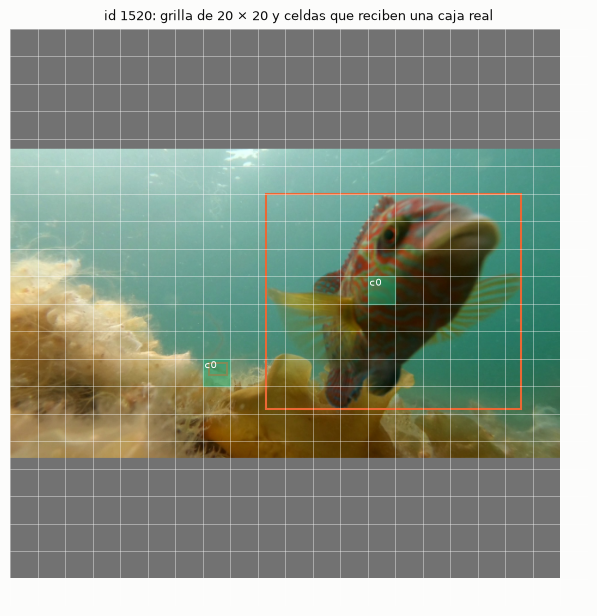

In [16]:
id_grilla = random.Random(SEMILLA).choice(particion["train"])
imagen, objetivos, _ = DatasetFjordFish("train", [id_grilla], aumentar=False)[0]
with torch.no_grad():
    cajas_iniciales = modelo_inicial.cajas(modelo_inicial(imagen[None].to(DISPOSITIVO).float() / 255).float())
_, _, asignada, _ = asignar_objetivos(cajas_iniciales, [objetivos])

fig, ax = plt.subplots(figsize=(7.5, 7.5))
dibujar_lienzo(ax, imagen, objetivos, f"id {id_grilla}: grilla de {GRILLA} × {GRILLA} y celdas que reciben una caja real")
lado_celda = LADO / GRILLA
for k in range(GRILLA + 1):
    ax.axhline(k * lado_celda, color="white", lw=0.4, alpha=0.7)
    ax.axvline(k * lado_celda, color="white", lw=0.4, alpha=0.7)
for fila, columna, candidata in asignada[0].nonzero().tolist():
    ax.add_patch(plt.Rectangle((columna * lado_celda, fila * lado_celda), lado_celda, lado_celda, color=AQUA, alpha=0.5))
    ax.text(columna * lado_celda + 2, fila * lado_celda + 11, f"c{candidata}", color="white", fontsize=7)
fig.savefig(DIR_RESULTADOS / "asignacion_en_la_grilla.png", dpi=120, bbox_inches="tight")
plt.show()

## 6. Función de pérdida

Es la pérdida del original, con otro peso para el fondo (D2):

pérdida = (`PESO_CAJA` · Σ error cuadrático de caja en las asignadas + `PESO_CLASE` · Σ entropía cruzada ponderada) / n.º de candidatas asignadas

En la variante de coordenadas relativas (D2), el error del centro se mide en unidades de celda, como en YOLOv1–v3: es el mismo error multiplicado por `GRILLA`. Medido en unidades del lienzo, su gradiente sería unas 400 veces menor y la variante quedaría en desventaja en la prueba de la sección 9.

La entropía cruzada se calcula en todas las candidatas: pesa 1 en las asignadas y `PESO_FONDO` en las de fondo (1/4000 en el original). Se calcula desde los logits, lo que da la misma pérdida que aplicar softmax y después la entropía cruzada (como hacía el original), pero con más estabilidad numérica. La pérdida se calcula siempre en float32, aunque la red corra en float16. La regularización L2 se aplica en el optimizador (sección 8).

In [17]:
def sumas_de_perdida(red, salida, objetivos):
    """Sumas sin normalizar, como el original: error de caja, error de clase ponderado, n.º de asignadas y de sin asignar."""
    cajas = red.cajas(salida)
    caja_obj, clase_obj, asignada, sin_asignar = asignar_objetivos(cajas.detach(), objetivos)
    diferencia = cajas - caja_obj
    if red.coordenadas_relativas:            # el centro se compara en unidades de celda, como en YOLOv1–v3
        diferencia = diferencia * torch.tensor([GRILLA, GRILLA, 1.0, 1.0], device=salida.device)
    error_caja = (diferencia ** 2).sum(dim=-1)[asignada].sum()
    entropia = F.cross_entropy(salida[..., 4:].reshape(-1, NUM_CLASES + 1), clase_obj.reshape(-1), reduction="none")
    pesos = torch.where(asignada.reshape(-1), 1.0, red.peso_fondo)
    return error_caja, (entropia * pesos).sum(), asignada.sum(), sin_asignar

Como hacía el cuaderno original antes de entrenar, se calcula la pérdida de un micro-lote con la red recién inicializada, y se verifican la forma de las imágenes y el rango de las clases.

La pérdida de clase por candidata asignada incluye también la de las candidatas de fondo. Si cada candidata parte con probabilidad de objeto p (`PROB_OBJETO_INICIAL`), repartida por igual entre las 28 clases, vale −ln(p / 28) − ln(1 − p) · peso total del fondo / asignadas. La celda imprime ese valor de referencia junto al calculado, que puede ser mayor porque los pesos iniciales de la cabeza son aleatorios.

In [18]:
cargador = lotes(datos_train, MICRO_LOTE)
imagenes, objetivos, _ = next(cargador)
cargador.close()                          # solo se necesita el primer lote
assert imagenes.shape == (MICRO_LOTE, 3, LADO, LADO) and imagenes.dtype == torch.uint8, f"lote inesperado: {imagenes.shape}"
assert all(((o[:, 0] >= 0) & (o[:, 0] < NUM_CLASES)).all() for o in objetivos), "Hay clases fuera de 0..27"

with torch.no_grad():
    salida = modelo_inicial(imagenes.to(DISPOSITIVO).float() / 255).float()
    error_caja, error_clase, n_asignadas, n_sin_asignar = sumas_de_perdida(modelo_inicial, salida, objetivos)
n = max(int(n_asignadas), 1)
peso_fondo_total = PESO_FONDO * (len(imagenes) * GRILLA * GRILLA * N_CANDIDATAS - n)
referencia = -math.log(PROB_OBJETO_INICIAL / NUM_CLASES) - math.log(1 - PROB_OBJETO_INICIAL) * peso_fondo_total / n
print(f"Cajas reales en el micro-lote: {sum(len(o) for o in objetivos)} | asignadas: {n} | sin asignar: {n_sin_asignar}")
print(f"Pérdida inicial por candidata asignada · caja: {error_caja.item() / n:.4f} | clase: {error_clase.item() / n:.4f} "
      f"(referencia con la probabilidad inicial: {referencia:.4f})")

Cajas reales en el micro-lote: 25 | asignadas: 25 | sin asignar: 0
Pérdida inicial por candidata asignada · caja: 0.5497 | clase: 8.4185 (referencia con la probabilidad inicial: 8.4188)


## 7. Decodificación y NMS

Estas funciones (y las de la sección 8) van antes de la prueba de sobreajuste porque esa prueba entrena variantes y mide su mAP. Para convertir la salida de la red en detecciones:
1. Cada candidata aporta una detección por cada clase (sin contar el fondo) cuya probabilidad alcanza `CONF_EVALUACION`, con esa probabilidad como confianza. Es el NMS **multietiqueta** que usa YOLO al calcular su mAP; Faster R-CNN también entrega una detección por clase.
2. Se descartan las cajas vacías y, si quedan más de `MAX_ANTES_NMS`, se conservan las más confiables (el mismo límite de Ultralytics).
3. Se aplica NMS por clase (IoU `IOU_NMS`) y se dejan hasta `MAX_DETECCIONES` por imagen.
4. Se deshace el letterbox para llevar las cajas a píxeles de la imagen de `datasets/fjordfish/`.

Son los mismos valores que usa YOLO al evaluar (confianza 0,001, IoU 0,5 y 300 detecciones), así las predicciones de ambos modelos se comparan en igualdad de condiciones. También se usa la misma precisión numérica que YOLO: float16 en la validación de cada época del entrenamiento y float32 en la evaluación final.

In [19]:
def inferir(red, imagenes, precision_mixta=True):
    """Pasa un lote de imágenes uint8 por la red en la GPU, normalizado a [0, 1]; en float16 si `precision_mixta`."""
    with torch.autocast(DISPOSITIVO.type, dtype=torch.float16, enabled=precision_mixta and USAR_AMP):
        return red(imagenes.to(DISPOSITIVO, non_blocking=True).float() / 255)


def postprocesar(red, salida, conf_minima=CONF_EVALUACION):
    """Salida cruda de un lote → por imagen: (cajas x1, y1, x2, y2 en px del lienzo, confianzas, clases), tras NMS."""
    salida = salida.float()
    cajas = red.cajas(salida).reshape(len(salida), -1, 4) * LADO
    probabilidades = salida[..., 4:].softmax(dim=-1).reshape(len(salida), -1, NUM_CLASES + 1)[..., :NUM_CLASES]   # sin el fondo
    detecciones = []
    for b in range(len(salida)):
        cx, cy, w, h = cajas[b].unbind(-1)
        xyxy = torch.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], dim=-1).clamp(0, LADO)
        no_vacia = (xyxy[:, 2] > xyxy[:, 0]) & (xyxy[:, 3] > xyxy[:, 1])
        # una detección por cada par (candidata, clase) que alcanza la confianza mínima (NMS multietiqueta)
        candidata, clase = torch.nonzero((probabilidades[b] >= conf_minima) & no_vacia[:, None], as_tuple=True)
        conf = probabilidades[b][candidata, clase]
        if len(conf) > MAX_ANTES_NMS:
            mejores = conf.topk(MAX_ANTES_NMS).indices
            candidata, clase, conf = candidata[mejores], clase[mejores], conf[mejores]
        quedan = batched_nms(xyxy[candidata], conf, clase, IOU_NMS)[:MAX_DETECCIONES]
        detecciones.append((xyxy[candidata[quedan]], conf[quedan], clase[quedan]))
    return detecciones


def a_filas(detecciones, lista_letterbox):
    """Detecciones en px del lienzo → filas del formato común, en px de la imagen de datasets/fjordfish."""
    filas = []
    for (xyxy, conf, cls), letterbox in zip(detecciones, lista_letterbox):
        xyxy = xyxy.cpu().numpy()
        x = ((xyxy[:, [0, 2]] - letterbox["dx"]) * letterbox["factor_x"]).clip(0, letterbox["ancho"])   # se deshace el letterbox
        y = ((xyxy[:, [1, 3]] - letterbox["dy"]) * letterbox["factor_y"]).clip(0, letterbox["alto"])
        for c, p, (x1, x2), (y1, y2) in zip(cls.tolist(), conf.tolist(), x.tolist(), y.tolist()):
            filas.append((letterbox["id"], c, round(p, 5), round(x1, 1), round(y1, 1), round(x2, 1), round(y2, 1)))
    return filas


@torch.no_grad()
def predecir(red, dataset, precision_mixta=False):
    """Detecciones de la red en un dataset sin aumento, en el formato común (por defecto en float32, como YOLO al evaluar)."""
    red.eval()
    filas = []
    for imagenes, _, lista_letterbox in lotes(dataset, LOTE_EVALUACION):
        filas += a_filas(postprocesar(red, inferir(red, imagenes, precision_mixta)), lista_letterbox)
    return pd.DataFrame(filas, columns=COLUMNAS_PREDICCIONES)

## 8. Optimizador y ciclo de entrenamiento

- **SGD con momentum** (`TASA_APRENDIZAJE`, `MOMENTUM`), como el original. Su regularización L2 (`LAMBDA_L2` · Σ w² sobre los kernels de las convoluciones) equivale a un `weight_decay` de 2 · `LAMBDA_L2` aplicado solo a esos kernels.
- **Precisión mixta:** el `GradScaler` multiplica la pérdida antes de retropropagar para que los gradientes en float16 no se vuelvan cero; `actualizar_pesos` deshace esa escala antes de dividir y actualizar.

In [20]:
def crear_optimizador(red):
    """SGD con momentum; la L2 del original (LAMBDA_L2 · Σ w² de los kernels) equivale a weight_decay = 2 · LAMBDA_L2."""
    kernels = [m.weight for m in red.modules() if isinstance(m, nn.Conv2d)]
    otros = [p for p in red.parameters() if all(p is not k for k in kernels)]     # sesgos y BatchNorm: sin L2
    optimizador = torch.optim.SGD([{"params": kernels, "weight_decay": 2 * LAMBDA_L2},
                                   {"params": otros, "weight_decay": 0.0}], lr=TASA_APRENDIZAJE, momentum=MOMENTUM)
    return optimizador, torch.amp.GradScaler("cuda", enabled=USAR_AMP)


def actualizar_pesos(red, optimizador, escalador, asignadas):
    """Divide los gradientes acumulados por las candidatas asignadas y actualiza; devuelve True si el paso se descartó."""
    escalador.unscale_(optimizador)
    for p in red.parameters():
        if p.grad is not None:
            p.grad /= max(asignadas, 1.0)
    escala_antes = escalador.get_scale()
    escalador.step(optimizador)
    escalador.update()
    optimizador.zero_grad(set_to_none=True)
    return escalador.get_scale() < escala_antes      # GradScaler baja la escala cuando descarta un paso con gradientes infinitos

- **Acumulación de gradientes**, igual que en el original: cada micro-lote de `MICRO_LOTE` imágenes suma sus gradientes y, cada `ACUMULAR` micro-lotes, se dividen por el total de candidatas asignadas y se actualizan los pesos.
- **Pasos descartados:** al comienzo, el `GradScaler` puede descartar algunos pasos mientras ajusta su escala (cuando los gradientes en float16 se desbordan). Se cuentan y se informan.
- **Validación en una sola pasada:** con la misma salida de la red se calculan la pérdida (normalizada igual que en entrenamiento), las detecciones y sus métricas, como hace YOLO.
- **Modo determinista**, igual que YOLO (`deterministic=True`): PyTorch usa algoritmos reproducibles donde existen. Algunas operaciones en la GPU, como el *max-pool*, no tienen versión determinista; PyTorch avisa y sigue (esos avisos se ocultan en la primera celda).

Estas funciones se usan tanto en la prueba de sobreajuste como en el entrenamiento completo.

In [21]:
def promedios(suma_caja, suma_clase, asignadas):
    """Pérdida total, de caja y de clase por candidata asignada."""
    n = max(asignadas, 1.0)
    return {"perdida": (PESO_CAJA * suma_caja + PESO_CLASE * suma_clase) / n,
            "perdida_caja": suma_caja / n, "perdida_clase": suma_clase / n}


def modo_determinista(activar):
    """Activa o desactiva los algoritmos deterministas de PyTorch, igual que YOLO con deterministic=True."""
    torch.use_deterministic_algorithms(activar, warn_only=True)
    torch.backends.cudnn.deterministic = activar
    torch.utils.deterministic.fill_uninitialized_memory = not activar   # Ultralytics también omite este relleno


def entrenar_epoca(red, dataset, optimizador, escalador):
    """Una época; cada ACUMULAR micro-lotes actualiza los pesos y, al final, avanza `dataset.epoca` (otro aumento)."""
    red.train()
    suma_caja = suma_clase = total_asignadas = 0.0
    asignadas_pendientes, pendientes, sin_asignar, descartados = 0.0, 0, 0, 0
    for imagenes, objetivos, _ in lotes(dataset, MICRO_LOTE, mezclar=True):
        salida = inferir(red, imagenes)
        error_caja, error_clase, n_asignadas, n_sin_asignar = sumas_de_perdida(red, salida.float(), objetivos)
        escalador.scale(PESO_CAJA * error_caja + PESO_CLASE * error_clase).backward()
        suma_caja += error_caja.item()
        suma_clase += error_clase.item()
        total_asignadas += n_asignadas.item()
        asignadas_pendientes += n_asignadas.item()
        sin_asignar += n_sin_asignar
        pendientes += 1
        if pendientes == ACUMULAR:
            descartados += actualizar_pesos(red, optimizador, escalador, asignadas_pendientes)
            asignadas_pendientes, pendientes = 0.0, 0
    if pendientes:                                   # micro-lotes que sobran al final de la época
        descartados += actualizar_pesos(red, optimizador, escalador, asignadas_pendientes)
    dataset.epoca += 1
    return {**promedios(suma_caja, suma_clase, total_asignadas), "sin_asignar": sin_asignar, "pasos_descartados": descartados}


@torch.no_grad()
def validar(red, dataset, reales):
    """Una pasada por un dataset sin aumento: pérdida del original, métricas del evaluador común y detecciones."""
    red.eval()
    suma_caja = suma_clase = total_asignadas = 0.0
    filas = []
    for imagenes, objetivos, lista_letterbox in lotes(dataset, LOTE_EVALUACION):
        salida = inferir(red, imagenes).float()        # float16, como la validación de YOLO durante el entrenamiento
        error_caja, error_clase, n_asignadas, _ = sumas_de_perdida(red, salida, objetivos)
        suma_caja += error_caja.item()
        suma_clase += error_clase.item()
        total_asignadas += n_asignadas.item()
        filas += a_filas(postprocesar(red, salida), lista_letterbox)
    detecciones = pd.DataFrame(filas, columns=COLUMNAS_PREDICCIONES)
    return promedios(suma_caja, suma_clase, total_asignadas), evaluar_detecciones(detecciones, reales), detecciones

## 9. Prueba de sobreajuste (D2)

Antes del entrenamiento largo se comprueba si la red **puede aprenderse `IMAGENES_SOBREAJUSTE` (16) imágenes de train sin aumento**. Si ni siquiera logra memorizarlas, el problema está en el diseño (asignación, pérdida o forma de predecir las cajas) y no en los hiperparámetros.

Se prueban estas variantes, con el mismo optimizador, las mismas imágenes y la misma semilla:
- **Con el peso del fondo del original (1/4000):**
  - **original:** el diseño del cuaderno del grupo, que predice el centro de la caja en coordenadas de toda la imagen;
  - **relativas:** el centro de la caja se predice relativo a su celda (sigmoide más la posición de la celda) y su error se mide en unidades de celda; el ancho y el alto se predicen con sigmoide;
  - **BatchNorm:** BatchNorm después de cada convolución;
  - **relativas y BatchNorm.**
- **Con otro peso del fondo**, y cada candidata partiendo con probabilidad de objeto `PROB_OBJETO_INICIAL`:
  - **relativas y BatchNorm, fondo 0,01, 0,1 y 1;**
  - **relativas, fondo 0,1**, sin BatchNorm.

Una variante aprende si su mAP50 sobre esas mismas imágenes se acerca a 1. La tabla muestra también:
- la pérdida final en modo evaluación (con BatchNorm difiere de la de entrenamiento, porque usa las estadísticas acumuladas);
- las candidatas por imagen marcadas como objeto, es decir, con probabilidad de objeto de al menos `UMBRAL_CONFIANZA` (estas imágenes tienen 1,5 objetos por imagen);
- cuántos pasos descartó el `GradScaler`.

La prueba corre en modo determinista, como el entrenamiento, y sirve como evidencia para la decisión D2 y su justificación (ítem 1.3). Con la GPU libre, las variantes tardan unos 20 minutos; con `PROBAR_SOBREAJUSTE = False` se muestra la prueba guardada.

> **En esta variante** la prueba no se repite: se muestra la guardada del cuaderno original (`../01_cnn_propia_desde_cero.ipynb`), hecha con 16 imágenes de la partición original. `PROBAR_SOBREAJUSTE` debe quedar en `False`.

In [22]:
FONDO_ORIGINAL = dict(peso_fondo=1 / 4000, prob_objeto_inicial=None)


def fondo(peso):
    """Opciones de una variante con otro peso del fondo y la probabilidad de objeto inicial de la configuración."""
    return dict(peso_fondo=peso, prob_objeto_inicial=PROB_OBJETO_INICIAL)


VARIANTES = {
    "original": dict(coordenadas_relativas=False, usar_batchnorm=False, **FONDO_ORIGINAL),
    "relativas": dict(coordenadas_relativas=True, usar_batchnorm=False, **FONDO_ORIGINAL),
    "BatchNorm": dict(coordenadas_relativas=False, usar_batchnorm=True, **FONDO_ORIGINAL),
    "relativas y BatchNorm": dict(coordenadas_relativas=True, usar_batchnorm=True, **FONDO_ORIGINAL),
    "relativas y BatchNorm, fondo 0,01": dict(coordenadas_relativas=True, usar_batchnorm=True, **fondo(0.01)),
    "relativas y BatchNorm, fondo 0,1": dict(coordenadas_relativas=True, usar_batchnorm=True, **fondo(0.1)),
    "relativas y BatchNorm, fondo 1": dict(coordenadas_relativas=True, usar_batchnorm=True, **fondo(1.0)),
    "relativas, fondo 0,1": dict(coordenadas_relativas=True, usar_batchnorm=False, **fondo(0.1)),
}
# Esta variante no repite la prueba: muestra la guardada del cuaderno original, hecha con 16 imágenes de su train
assert not PROBAR_SOBREAJUSTE, "En esta variante la prueba no se repite: se muestra la del cuaderno original"
DIR_DATASET_ORIGINAL = DIR_ORIGINAL / "datasets" / "fjordfish"
DIR_PRUEBA_GUARDADA = DIR_ORIGINAL / "resultados" / "cnn_propia"
ids_train_original = (DIR_ORIGINAL / "splits" / "train.txt").read_text().split()
ids_sobreajuste = sorted(random.Random(SEMILLA).sample(ids_train_original, IMAGENES_SOBREAJUSTE))
datos_sobreajuste = DatasetFjordFish("train", ids_sobreajuste, aumentar=False)
reales_sobreajuste = cargar_cajas_reales(DIR_DATASET_ORIGINAL, "train", ids_sobreajuste)
COLUMNA_MAP50 = f"mAP50 en las {IMAGENES_SOBREAJUSTE} imágenes"


@torch.no_grad()
def candidatas_marcadas(red, dataset):
    """Candidatas por imagen cuya probabilidad de objeto (1 − probabilidad de fondo) alcanza UMBRAL_CONFIANZA."""
    red.eval()
    marcadas = 0
    for imagenes, _, _ in lotes(dataset, LOTE_EVALUACION):
        probabilidades = inferir(red, imagenes, False).float()[..., 4:].softmax(dim=-1)
        marcadas += (1 - probabilidades[..., FONDO] >= UMBRAL_CONFIANZA).sum().item()
    return marcadas / len(dataset)


def probar_variante(opciones):
    """Entrena una variante sobre las imágenes de la prueba; devuelve su curva de pérdida, sus predicciones y sus métricas."""
    random.seed(SEMILLA)                  # todas las variantes parten igual y ven las imágenes en el mismo orden
    torch.manual_seed(SEMILLA)
    red = DetectorCNN(ARQUITECTURA, **opciones).to(DISPOSITIVO)
    optimizador, escalador = crear_optimizador(red)
    t_inicio = time.perf_counter()
    curva, descartados = [], 0
    for _ in range(EPOCAS_SOBREAJUSTE):
        perdidas = entrenar_epoca(red, datos_sobreajuste, optimizador, escalador)
        curva.append(perdidas["perdida"])
        descartados += perdidas["pasos_descartados"]
    perdidas_eval, metricas_variante, pred = validar(red, datos_sobreajuste, reales_sobreajuste)
    fila = {"pérdida en la época 1": curva[0], "pérdida final (entrenamiento)": curva[-1],
            "pérdida final (modo evaluación)": perdidas_eval["perdida"], COLUMNA_MAP50: metricas_variante["mAP50"],
            f"mAP50-95 en las {IMAGENES_SOBREAJUSTE} imágenes": metricas_variante["mAP50_95"],
            "candidatas marcadas por imagen": candidatas_marcadas(red, datos_sobreajuste),
            "pasos descartados": descartados, "minutos": (time.perf_counter() - t_inicio) / 60}
    return curva, pred, fila


if PROBAR_SOBREAJUSTE:
    modo_determinista(True)
    curvas_sobreajuste, predicciones_sobreajuste, filas = {}, {}, {}
    for nombre, opciones in VARIANTES.items():
        curvas_sobreajuste[nombre], predicciones_sobreajuste[nombre], filas[nombre] = probar_variante(opciones)
        print(f"{nombre:22s} pérdida {curvas_sobreajuste[nombre][0]:.3f} → {curvas_sobreajuste[nombre][-1]:.4f} | "
              f"mAP50 {filas[nombre][COLUMNA_MAP50]:.3f} | {filas[nombre]['minutos']:.1f} min")
        torch.cuda.empty_cache()
    modo_determinista(False)
    tabla_sobreajuste = pd.DataFrame(filas).T.rename_axis("variante")
    tabla_sobreajuste.to_csv(DIR_RESULTADOS / "prueba_sobreajuste.csv")
    pd.DataFrame(curvas_sobreajuste).rename_axis("época").to_csv(DIR_RESULTADOS / "prueba_sobreajuste_curvas.csv")
    pd.concat([p.assign(variante=v) for v, p in predicciones_sobreajuste.items()]).to_csv(
        DIR_RESULTADOS / "prueba_sobreajuste_predicciones.csv", index=False)
else:                                     # se muestra la prueba guardada, sin repetirla
    assert (DIR_PRUEBA_GUARDADA / "prueba_sobreajuste.csv").exists(), "No hay una prueba guardada: usar PROBAR_SOBREAJUSTE = True"
    tabla_sobreajuste = pd.read_csv(DIR_PRUEBA_GUARDADA / "prueba_sobreajuste.csv", index_col="variante")
    curvas_sobreajuste = pd.read_csv(DIR_PRUEBA_GUARDADA / "prueba_sobreajuste_curvas.csv", index_col="época").to_dict("list")
    guardadas = pd.read_csv(DIR_PRUEBA_GUARDADA / "prueba_sobreajuste_predicciones.csv", dtype={"id": str})
    predicciones_sobreajuste = {v: g.drop(columns="variante") for v, g in guardadas.groupby("variante", sort=False)}
tabla_sobreajuste.round(4)

,pérdida en la época 1,pérdida final (entrenamiento),pérdida final (modo evaluación),mAP50 en las 16 imágenes,mAP50-95 en las 16 imágenes,candidatas marcadas por imagen,pasos descartados,minutos
variante,,,,,,,,
original,7.6100,2.4067,2.4606,0.0001,0.0000,616.0000,7.0,2.1343
relativas,7.0598,2.5849,2.7604,0.0002,0.0000,1784.7500,5.0,2.2007
BatchNorm,20.7341,NaN,NaN,0.0000,0.0000,0.0000,166.0,2.2674
relativas y BatchNorm,7.4040,0.2744,0.9140,0.1955,0.0941,417.8125,7.0,2.3419
"relativas y BatchNorm, fondo 0,01",10.1792,1.2330,0.6618,0.4594,0.1711,14.3125,8.0,2.3493
"relativas y BatchNorm, fondo 0,1",17.7947,0.8514,0.8141,0.7295,0.2665,3.4375,7.0,2.3517
"relativas y BatchNorm, fondo 1",93.9497,5.1547,4.5048,0.2229,0.1025,0.8750,9.0,2.3514
"relativas, fondo 0,1",12.0675,7.2138,6.8789,0.0002,0.0000,0.0000,5.0,2.1746


Izquierda: la pérdida de cada variante época a época, en escala logarítmica; las líneas discontinuas usan el peso del fondo del original. Esa pérdida solo se compara entre variantes con el mismo peso del fondo, porque ese peso cambia su escala. Derecha: el mAP50 de cada variante sobre las mismas imágenes con que entrenó (1 = encuentra todas las cajas).

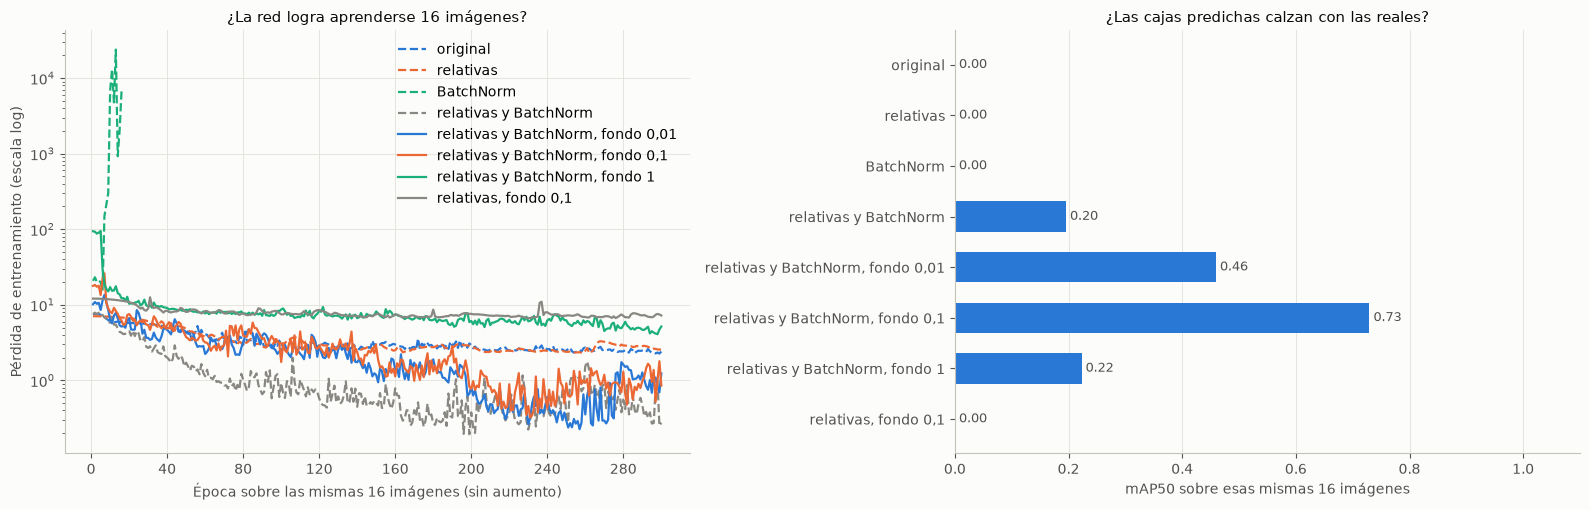

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
for (nombre, curva), color, linea in zip(curvas_sobreajuste.items(), [AZUL, NARANJA, AQUA, GRIS] * 2, ["--"] * 4 + ["-"] * 4):
    axes[0].plot(range(1, len(curva) + 1), curva, color=color, ls=linea, lw=1.6, label=nombre)
axes[0].set_yscale("log")
axes[0].set_xlabel(f"Época sobre las mismas {IMAGENES_SOBREAJUSTE} imágenes (sin aumento)")
axes[0].set_ylabel("Pérdida de entrenamiento (escala log)")
axes[0].set_title(f"¿La red logra aprenderse {IMAGENES_SOBREAJUSTE} imágenes?")
axes[0].legend()
epocas_enteras(axes[0])
mapas = tabla_sobreajuste[COLUMNA_MAP50]
axes[1].barh(mapas.index[::-1], mapas.values[::-1], height=0.6, color=AZUL)
for yi, v in enumerate(mapas.values[::-1]):
    axes[1].text(v, yi, f" {v:.2f}", va="center", fontsize=9, color="#52514e")
axes[1].set_xlim(0, 1.1)
axes[1].set_xlabel(f"mAP50 sobre esas mismas {IMAGENES_SOBREAJUSTE} imágenes")
axes[1].set_title("¿Las cajas predichas calzan con las reales?")
axes[1].grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(DIR_RESULTADOS / "prueba_sobreajuste.png", dpi=150, bbox_inches="tight")
plt.show()

Las predicciones de cada variante sobre una de las imágenes de la prueba (confianza ≥ `UMBRAL_CONFIANZA`), junto a sus cajas reales. Cada título indica cuántas detecciones superan el umbral.

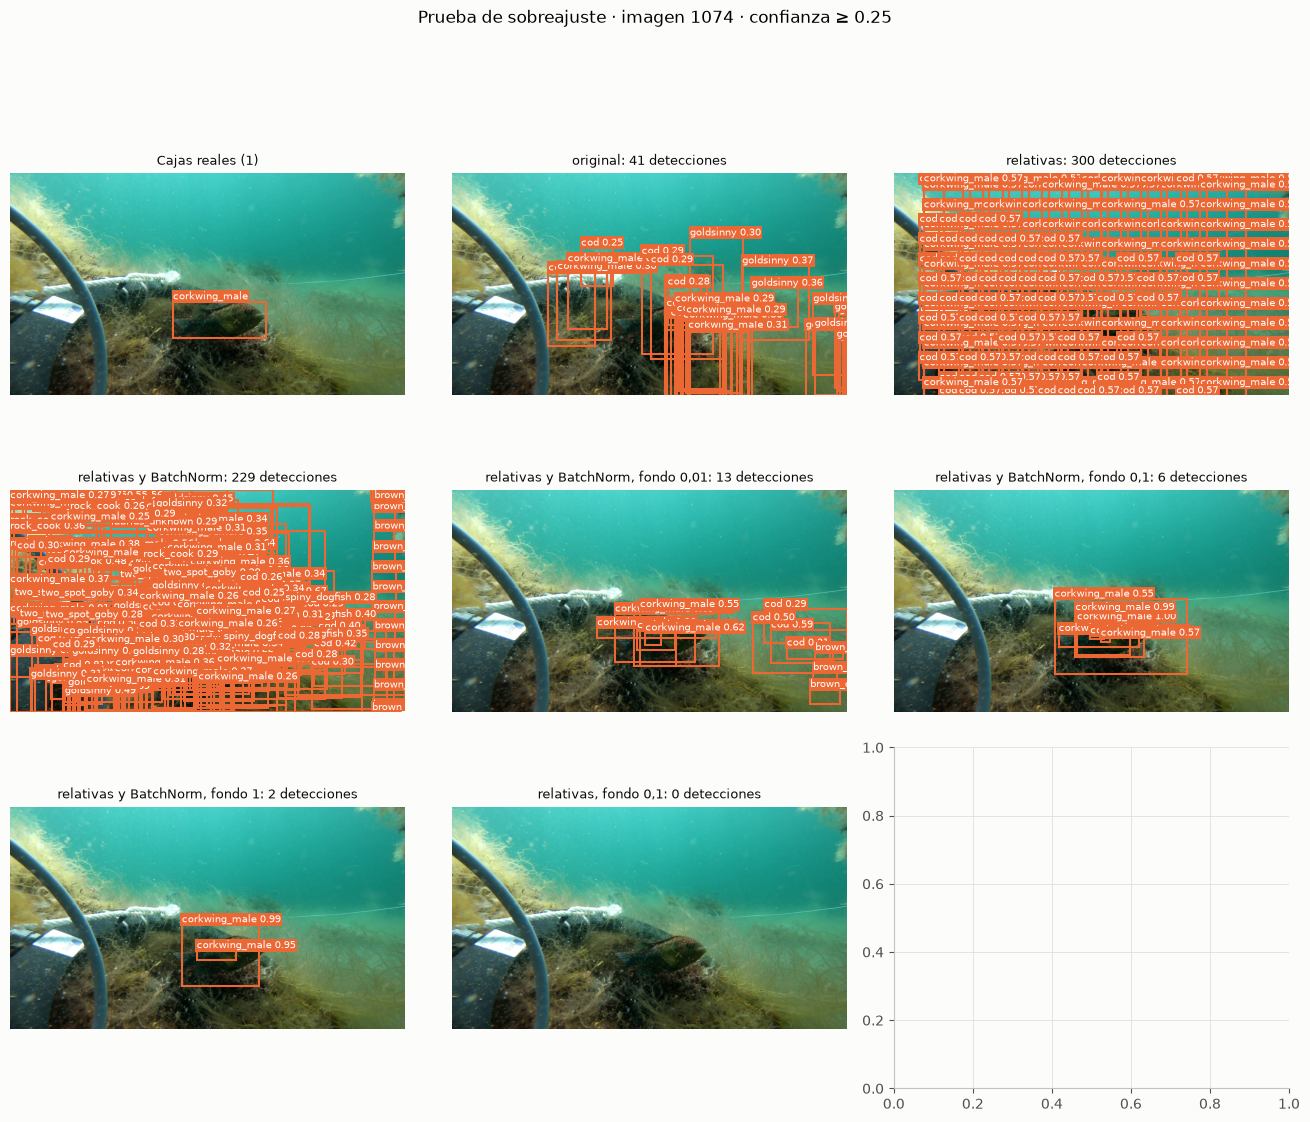

In [24]:
id_ejemplo = ids_sobreajuste[0]
img_ejemplo = Image.open(DIR_DATASET_ORIGINAL / "images" / "train" / f"{id_ejemplo}.jpg")
reales_ejemplo = reales_sobreajuste[reales_sobreajuste.id == id_ejemplo]
fig, axes = plt.subplots(3, 3, figsize=(13.2, 11.4))     # las cajas reales y las 8 variantes
axes = axes.ravel()
dibujar_cajas(axes[0], img_ejemplo, reales_ejemplo, f"Cajas reales ({len(reales_ejemplo)})")
for ax, (nombre, pred) in zip(axes[1:], predicciones_sobreajuste.items()):
    pred = pred[(pred.id == id_ejemplo) & (pred.confianza >= UMBRAL_CONFIANZA)]
    dibujar_cajas(ax, img_ejemplo, pred, f"{nombre}: {len(pred)} detecciones")
fig.suptitle(f"Prueba de sobreajuste · imagen {id_ejemplo} · confianza ≥ {UMBRAL_CONFIANZA}", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(DIR_RESULTADOS / "prueba_sobreajuste_ejemplo.png", dpi=120, bbox_inches="tight")
plt.show()

> ✍️ *Decisión del grupo sobre D2 a partir de esta prueba (qué variante se entrena y por qué): completar. La variante elegida se fija con `COORDENADAS_RELATIVAS`, `USAR_BATCHNORM`, `PESO_FONDO` y `PROB_OBJETO_INICIAL` en la configuración.*

## 10. Entrenamiento

Se entrena la variante de la configuración durante hasta `EPOCAS` épocas. Después de cada época se calculan la pérdida de validación y el mAP de validación (con el evaluador común) y se guardan los pesos de la mejor época según `CRITERIO_PARADA`; si no mejora en `PACIENCIA` épocas, el entrenamiento se detiene (parada temprana, como el original). El tiempo de cada época incluye la validación, igual que en YOLO, y el entrenamiento corre en modo determinista, también como YOLO. Test no se usa en esta sección.

En `~/tarea2_runs_80_10_10/reales/cnn_propia/` (fuera de OneDrive) quedan `mejor.pt` (pesos de la mejor época), `historial_completo.csv` (métricas por época, que se actualiza en cada época y permite seguir el avance) e `info_entrenamiento.json` (configuración, tiempo total y memoria de la GPU).

In [25]:
reales_val = cargar_cajas_reales(DIR_DATASET, "val", particion["val"])
PESOS = DIR_RUNS / "mejor.pt"
configuracion = {
    "coordenadas_relativas": COORDENADAS_RELATIVAS, "usar_batchnorm": USAR_BATCHNORM, "lado": LADO,
    "n_candidatas": N_CANDIDATAS, "peso_caja": PESO_CAJA, "peso_clase": PESO_CLASE, "peso_fondo": PESO_FONDO,
    "prob_objeto_inicial": PROB_OBJETO_INICIAL,
    "lambda_l2": LAMBDA_L2, "epocas": EPOCAS, "paciencia": PACIENCIA, "criterio_parada": CRITERIO_PARADA,
    "tasa_aprendizaje": TASA_APRENDIZAJE, "momentum": MOMENTUM, "micro_lote": MICRO_LOTE, "acumular": ACUMULAR,
    "precision_mixta": USAR_AMP,
}
aumento_datos = {"escala": ESCALA, "traslacion": TRASLACION, "hsv": [HSV_H, HSV_S, HSV_V], "volteo": VOLTEO, "mosaico": 0.0}

if ENTRENAR:
    random.seed(SEMILLA)
    torch.manual_seed(SEMILLA)
    modelo = DetectorCNN(ARQUITECTURA, COORDENADAS_RELATIVAS, USAR_BATCHNORM).to(DISPOSITIVO)
    optimizador, escalador = crear_optimizador(modelo)
    PESOS.unlink(missing_ok=True)                 # así nunca se carga el mejor.pt de un entrenamiento anterior
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
    modo_determinista(True)                       # como YOLO (deterministic=True)
    filas_historial, mejor_valor, mejor_epoca, sin_mejora = [], math.inf, 0, 0
    t_inicio = time.perf_counter()
    for epoca in range(1, EPOCAS + 1):
        perdidas_train = entrenar_epoca(modelo, datos_train, optimizador, escalador)
        perdidas_val, metricas_val, _ = validar(modelo, datos_val, reales_val)
        filas_historial.append({
            "epoca": epoca, "tiempo_s": time.perf_counter() - t_inicio,
            "perdida_train": perdidas_train["perdida"], "perdida_val": perdidas_val["perdida"],
            "val_mAP50": metricas_val["mAP50"], "val_mAP50_95": metricas_val["mAP50_95"],
            "perdida_caja_train": perdidas_train["perdida_caja"], "perdida_caja_val": perdidas_val["perdida_caja"],
            "perdida_clase_train": perdidas_train["perdida_clase"], "perdida_clase_val": perdidas_val["perdida_clase"],
            "cajas_sin_asignar": perdidas_train["sin_asignar"], "pasos_descartados": perdidas_train["pasos_descartados"]})
        pd.DataFrame(filas_historial).to_csv(DIR_RUNS / "historial_completo.csv", index=False)
        # se minimiza: la pérdida de validación o el mAP50-95 de validación con signo cambiado
        valor = perdidas_val["perdida"] if CRITERIO_PARADA == "perdida_val" else -metricas_val["mAP50_95"]
        if valor < mejor_valor:
            mejor_valor, mejor_epoca, sin_mejora = valor, epoca, 0
            torch.save(modelo.state_dict(), PESOS)
        else:
            sin_mejora += 1
        fila = filas_historial[-1]
        print(f"época {epoca:3d} | pérdida train {fila['perdida_train']:.4f} · val {fila['perdida_val']:.4f} | "
              f"val mAP50 {fila['val_mAP50']:.3f} · mAP50-95 {fila['val_mAP50_95']:.3f} | {fila['tiempo_s'] / 60:5.1f} min")
        if epoca == 1:
            print(f"  ≈ {fila['tiempo_s'] / 60:.1f} min por época → {EPOCAS} épocas ≈ {fila['tiempo_s'] * EPOCAS / 3600:.1f} h como máximo")
        if sin_mejora >= PACIENCIA:
            print(f"Parada temprana: {PACIENCIA} épocas sin mejorar {CRITERIO_PARADA} (mejor época: {mejor_epoca})")
            break
    modo_determinista(False)
    assert mejor_epoca >= 1, "Ninguna época mejoró el criterio de parada (¿pérdida NaN?): no hay pesos que cargar"
    info_entrenamiento = {
        "modelo": "CNN propia", "tiempo_entrenamiento_s": round(time.perf_counter() - t_inicio, 1),
        "memoria_gpu_max_GB": round(torch.cuda.max_memory_reserved() / 1e9, 2) if torch.cuda.is_available() else None,
        "dispositivo": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
        "mejor_epoca": mejor_epoca, "configuracion": configuracion, "aumento_datos": aumento_datos,
        "fraccion_train": FRACCION_TRAIN, "semilla": SEMILLA, "huella_particion": huella,
    }
    (DIR_RUNS / "info_entrenamiento.json").write_text(json.dumps(info_entrenamiento, indent=2), encoding="utf-8")

Se carga la mejor época, que es la que se evalúa desde aquí en adelante. Con `ENTRENAR = False` se leen el historial y la información guardados.

In [26]:
historial = pd.read_csv(DIR_RUNS / "historial_completo.csv")
info_entrenamiento = json.loads((DIR_RUNS / "info_entrenamiento.json").read_text(encoding="utf-8"))
config_guardada = info_entrenamiento["configuracion"]
modelo = DetectorCNN(ARQUITECTURA, config_guardada["coordenadas_relativas"], config_guardada["usar_batchnorm"]).to(DISPOSITIVO)
modelo.load_state_dict(torch.load(PESOS, map_location=DISPOSITIVO))
modelo.eval()
mejor_epoca = info_entrenamiento["mejor_epoca"]
tiempo_por_epoca_s = float(historial.tiempo_s.iloc[-1] / len(historial))
print(f"Tiempo total de entrenamiento: {info_entrenamiento['tiempo_entrenamiento_s'] / 60:.1f} min | "
      f"épocas: {len(historial)} | mejor época: {mejor_epoca} | tiempo medio por época: {tiempo_por_epoca_s:.1f} s")

Tiempo total de entrenamiento: 80.1 min | épocas: 65 | mejor época: 40 | tiempo medio por época: 73.9 s


## 11. Curvas de entrenamiento

Pérdidas de entrenamiento y validación por época (total, de caja y de clase, por candidata asignada) y mAP de validación. La línea discontinua marca la mejor época.

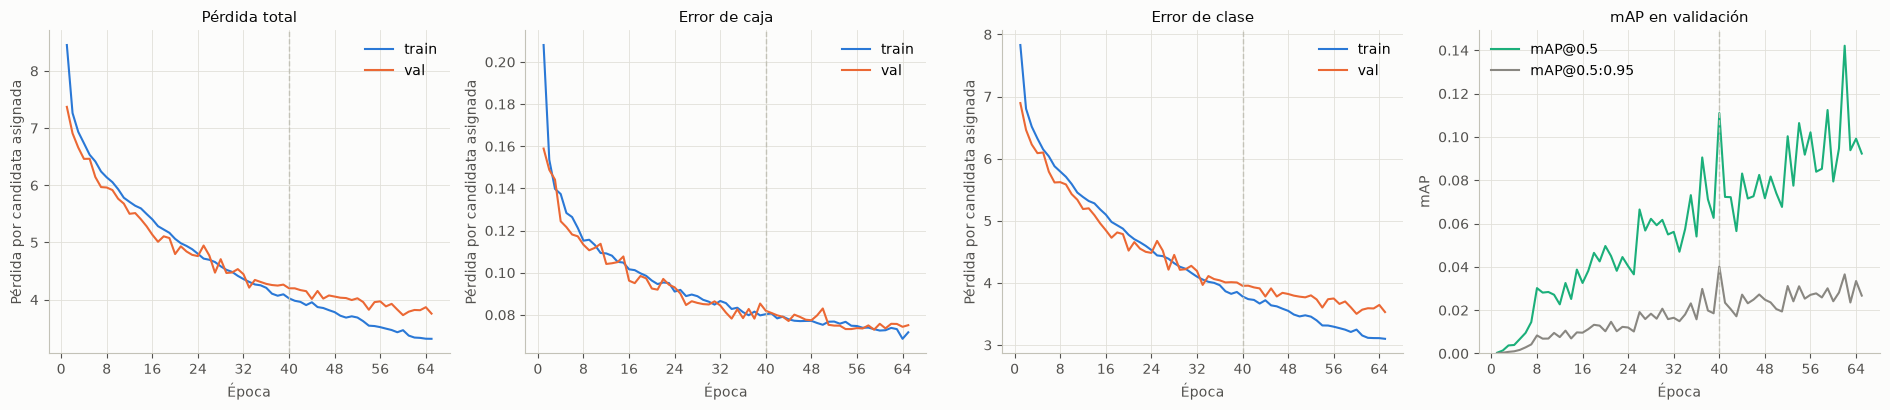

In [27]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))
for ax, (base, titulo) in zip(axes, [("perdida", "Pérdida total"), ("perdida_caja", "Error de caja"),
                                     ("perdida_clase", "Error de clase")]):
    ax.plot(historial.epoca, historial[f"{base}_train"], color=AZUL, lw=1.5, label="train")
    ax.plot(historial.epoca, historial[f"{base}_val"], color=NARANJA, lw=1.5, label="val")
    ax.set_title(titulo)
    ax.set_ylabel("Pérdida por candidata asignada")
    ax.legend()
axes[3].plot(historial.epoca, historial.val_mAP50, color=AQUA, lw=1.5, label="mAP@0.5")
axes[3].plot(historial.epoca, historial.val_mAP50_95, color=GRIS, lw=1.5, label="mAP@0.5:0.95")
axes[3].set_title("mAP en validación")
axes[3].set_ylabel("mAP")
axes[3].set_ylim(0, None)
axes[3].legend()
for ax in axes:
    ax.set_xlabel("Época")
    ax.axvline(mejor_epoca, color="#c3c2b7", ls="--", lw=1)
    epocas_enteras(ax)
fig.tight_layout()
fig.savefig(DIR_RESULTADOS / "curvas_entrenamiento.png", dpi=150, bbox_inches="tight")
plt.show()

## 12. Evaluación en validación y test (evaluador común)

Se evalúa la mejor época en validación y, una sola vez, en test, en float32 (como `val` de Ultralytics) y con el evaluador común de `comun.py`, el mismo que se usa para todos los modelos:
- **mAP50, mAP75 y mAP50-95** (definición COCO), promediando las clases con instancias en el conjunto evaluado;
- **precisión, recall y F1** con IoU 0,5 y confianza ≥ `UMBRAL_CONFIANZA`, promediados entre clases. Es el umbral común que fijó el grupo (D8), y `05_comparacion.ipynb` los recalcula con el mismo evaluador para todos los modelos.

In [28]:
CLAVES_METRICAS = ("precision", "recall", "F1", "mAP50", "mAP75", "mAP50_95")
predicciones, metricas = {}, {}
for split, dataset in (("val", datos_val), ("test", datos_test)):
    predicciones[split] = predecir(modelo, dataset)
    reales = cargar_cajas_reales(DIR_DATASET, split, particion[split])
    metricas[split] = evaluar_detecciones(predicciones[split], reales, nombres=NOMBRES, umbral_confianza=UMBRAL_CONFIANZA)
    print(f"{split}: {len(predicciones[split])} detecciones en {predicciones[split].id.nunique()} imágenes")

tabla_global = pd.DataFrame({s: {k: m[k] for k in CLAVES_METRICAS} for s, m in metricas.items()}).T.rename_axis("partición")
tabla_global.to_csv(DIR_RESULTADOS / "metricas_val_test.csv")
tabla_global.round(4)

val: 86877 detecciones en 301 imágenes


test: 87322 detecciones en 301 imágenes


,precision,recall,F1,mAP50,mAP75,mAP50_95
partición,,,,,,
val,0.0845,0.1333,0.1035,0.1244,0.0286,0.0418
test,0.0752,0.1295,0.0952,0.0741,0.0017,0.0203


AP por clase en test (solo aparecen las clases con instancias en test).

In [29]:
por_clase = metricas["test"]["por_clase"]
por_clase.to_csv(DIR_RESULTADOS / "metricas_por_clase_test.csv", index=False)
por_clase.sort_values("instancias", ascending=False).reset_index(drop=True).round(4)

,clase_id,clase,instancias,predicciones,AP50,AP75,AP50_95
0,5,goldsinny,159,29138,0.0145,0.0001,0.0028
1,4,corkwing_male,117,10083,0.2642,0.0058,0.0741
2,8,cod,87,11066,0.2453,0.0104,0.0642
3,16,spiny_dogfish,51,2829,0.2957,0.0189,0.0953
4,3,corkwing_female,51,9831,0.0477,0.0005,0.0089
5,15,gadines_unknown,36,2383,0.0103,0.0013,0.0035
6,7,labrids_unknown,34,6971,0.0044,0.0000,0.0007
7,18,brown_crab,18,1382,0.0050,0.0000,0.0010
8,9,cod_yoy,14,2132,0.0248,0.0000,0.0066
9,11,pollack,13,2140,0.0657,0.0010,0.0124


El mismo AP50 por clase como gráfico, de menor a mayor, con el número de instancias de cada clase en test.

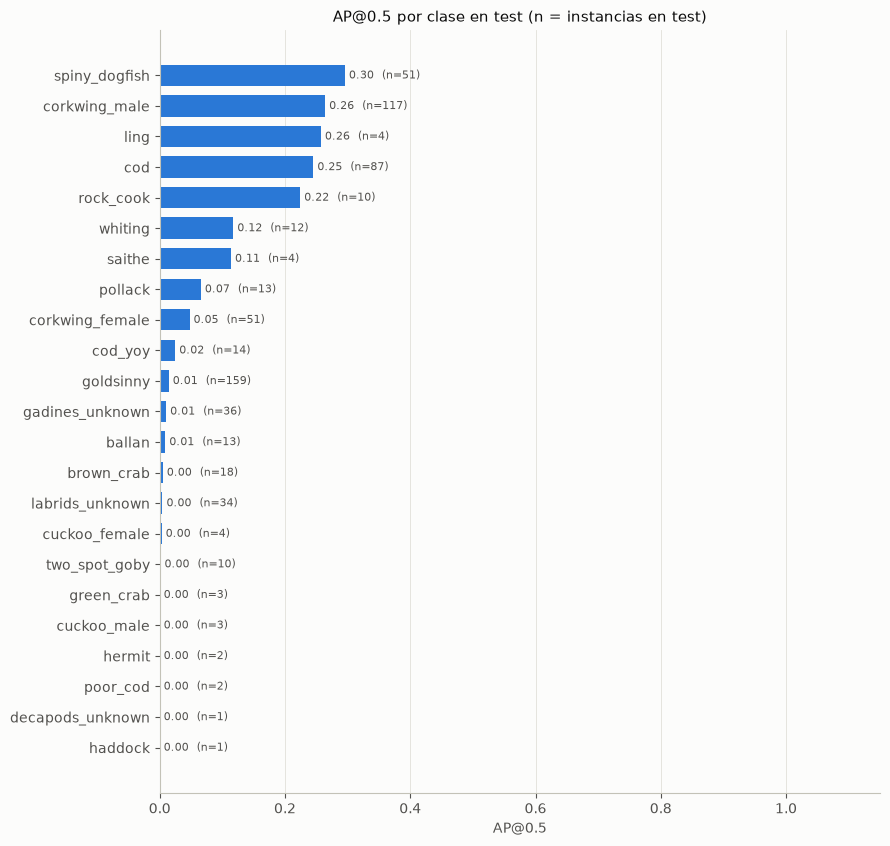

In [30]:
barras = por_clase.sort_values(["AP50", "instancias"])
fig, ax = plt.subplots(figsize=(9, 0.32 * len(barras) + 1.2))
ax.barh(barras.clase, barras.AP50, height=0.7, color=AZUL)
for yi, (v, n) in enumerate(zip(barras.AP50, barras.instancias)):
    ax.text(v, yi, f" {v:.2f}  (n={n})", va="center", fontsize=8, color="#52514e")
ax.set_xlim(0, 1.15)
ax.set_xlabel("AP@0.5")
ax.set_title("AP@0.5 por clase en test (n = instancias en test)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(DIR_RESULTADOS / "ap50_por_clase_test.png", dpi=150, bbox_inches="tight")
plt.show()

Curva precisión-recall en test con IoU 0,5: la precisión media entre clases para cada nivel de recall. El área bajo la curva es el mAP50.

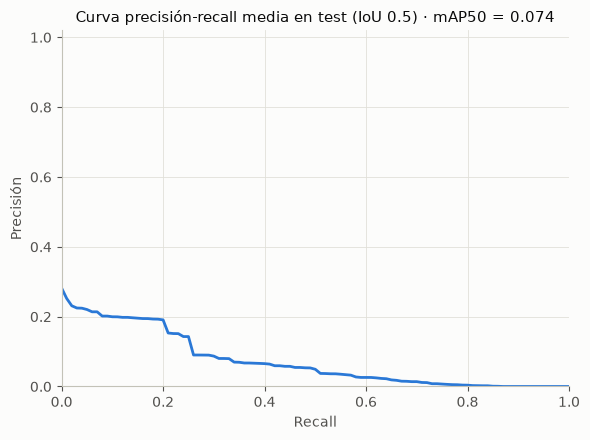

In [31]:
curva = metricas["test"]["curva_pr"]
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(curva.recall, curva.precision, color=AZUL, lw=2)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_xlabel("Recall")
ax.set_ylabel("Precisión")
ax.set_title(f"Curva precisión-recall media en test (IoU 0.5) · mAP50 = {metricas['test']['mAP50']:.3f}")
fig.tight_layout()
fig.savefig(DIR_RESULTADOS / "curva_pr_test.png", dpi=150, bbox_inches="tight")
plt.show()

## 13. Eficiencia: tamaño del modelo y velocidad de inferencia

Se miden los parámetros, los GFLOPs a 640 × 640, el tamaño del archivo de pesos y la velocidad con **lote de 1 imagen** sobre imágenes de test, después de un calentamiento. El tiempo se separa en preproceso (letterbox y paso a la GPU), inferencia y postproceso (decodificación y NMS), con las mismas claves que reporta Ultralytics. Son las mismas mediciones de `02_yolo_desde_cero.ipynb`, también en float32 y solo con las detecciones de confianza ≥ `UMBRAL_CONFIANZA` (como `predict` de Ultralytics).

La CNN siempre recibe un lienzo de 640 × 640 porque su cabeza supone una grilla cuadrada. Los cuadernos de YOLO se miden con ese mismo lienzo (`rect=False`), para que todos los modelos procesen la misma cantidad de píxeles.

In [32]:
def sincronizar():
    """Espera a que la GPU termine, para medir tiempos reales."""
    if DISPOSITIVO.type == "cuda":
        torch.cuda.synchronize()


@torch.no_grad()
def medir_tiempos(ruta):
    """Milisegundos de preproceso, inferencia y postproceso de una imagen con lote 1 (ya leída de disco), en float32."""
    original = cv2.imread(str(ruta))
    sincronizar()
    t0 = time.perf_counter()
    lienzo, *_ = ubicar_en_lienzo(redimensionar(original), np.zeros((0, 4)))
    imagen = torch.from_numpy(np.ascontiguousarray(lienzo[..., ::-1].transpose(2, 0, 1)))[None]
    imagen = imagen.to(DISPOSITIVO).float() / 255
    sincronizar()
    t1 = time.perf_counter()
    salida = modelo(imagen)
    sincronizar()
    t2 = time.perf_counter()
    postprocesar(modelo, salida, conf_minima=UMBRAL_CONFIANZA)
    sincronizar()
    t3 = time.perf_counter()
    return {"preprocess": (t1 - t0) * 1000, "inference": (t2 - t1) * 1000, "postprocess": (t3 - t2) * 1000}

Se miden `N_IMAGENES_VELOCIDAD` imágenes de test con lote 1 y, aparte, el tiempo de inferencia por imagen con lotes de `LOTE_EVALUACION` imágenes (`ms_inferencia_en_lote`). Para este último se usan imágenes al azar, porque el tiempo de la red no depende del contenido de la imagen.

In [33]:
for ruta in rutas_test[:10]:                     # calentamiento
    medir_tiempos(ruta)
tiempos = pd.DataFrame([medir_tiempos(ruta) for ruta in rutas_test[:N_IMAGENES_VELOCIDAD]])
ms_total = float(tiempos.sum(axis=1).mean())

lote_prueba = torch.rand(LOTE_EVALUACION, 3, LADO, LADO, device=DISPOSITIVO)
with torch.no_grad():                            # float32, como la evaluación de YOLO
    for _ in range(3):                           # calentamiento
        modelo(lote_prueba)
    sincronizar()
    t_inicio = time.perf_counter()
    for _ in range(10):
        modelo(lote_prueba)
    sincronizar()
ms_inferencia_en_lote = (time.perf_counter() - t_inicio) * 1000 / (10 * LOTE_EVALUACION)

n_parametros, gflops = tamano_de_la_red(modelo)   # de la variante entrenada
eficiencia = {
    "parametros_M": n_parametros / 1e6,
    "GFLOPs": gflops,
    "tamano_pesos_MB": PESOS.stat().st_size / 1e6,
    "ms_preproceso": float(tiempos.preprocess.mean()),
    "ms_inferencia": float(tiempos.inference.mean()),
    "ms_postproceso": float(tiempos.postprocess.mean()),
    "ms_total_por_imagen": ms_total,
    "FPS": 1000 / ms_total,
    "ms_inferencia_en_lote": ms_inferencia_en_lote,
}
pd.Series(eficiencia).round(3).to_frame("valor")

,valor
parametros_M,28.652
GFLOPs,72.701
tamano_pesos_MB,114.669
ms_preproceso,3.640
ms_inferencia,11.986
ms_postproceso,2.276
ms_total_por_imagen,17.901
FPS,55.862
ms_inferencia_en_lote,11.748


## 14. Resultados cualitativos

Las mismas imágenes de test que muestra el cuaderno de YOLO (misma semilla): anotación real a la izquierda y predicción a la derecha (confianza ≥ `UMBRAL_CONFIANZA`).

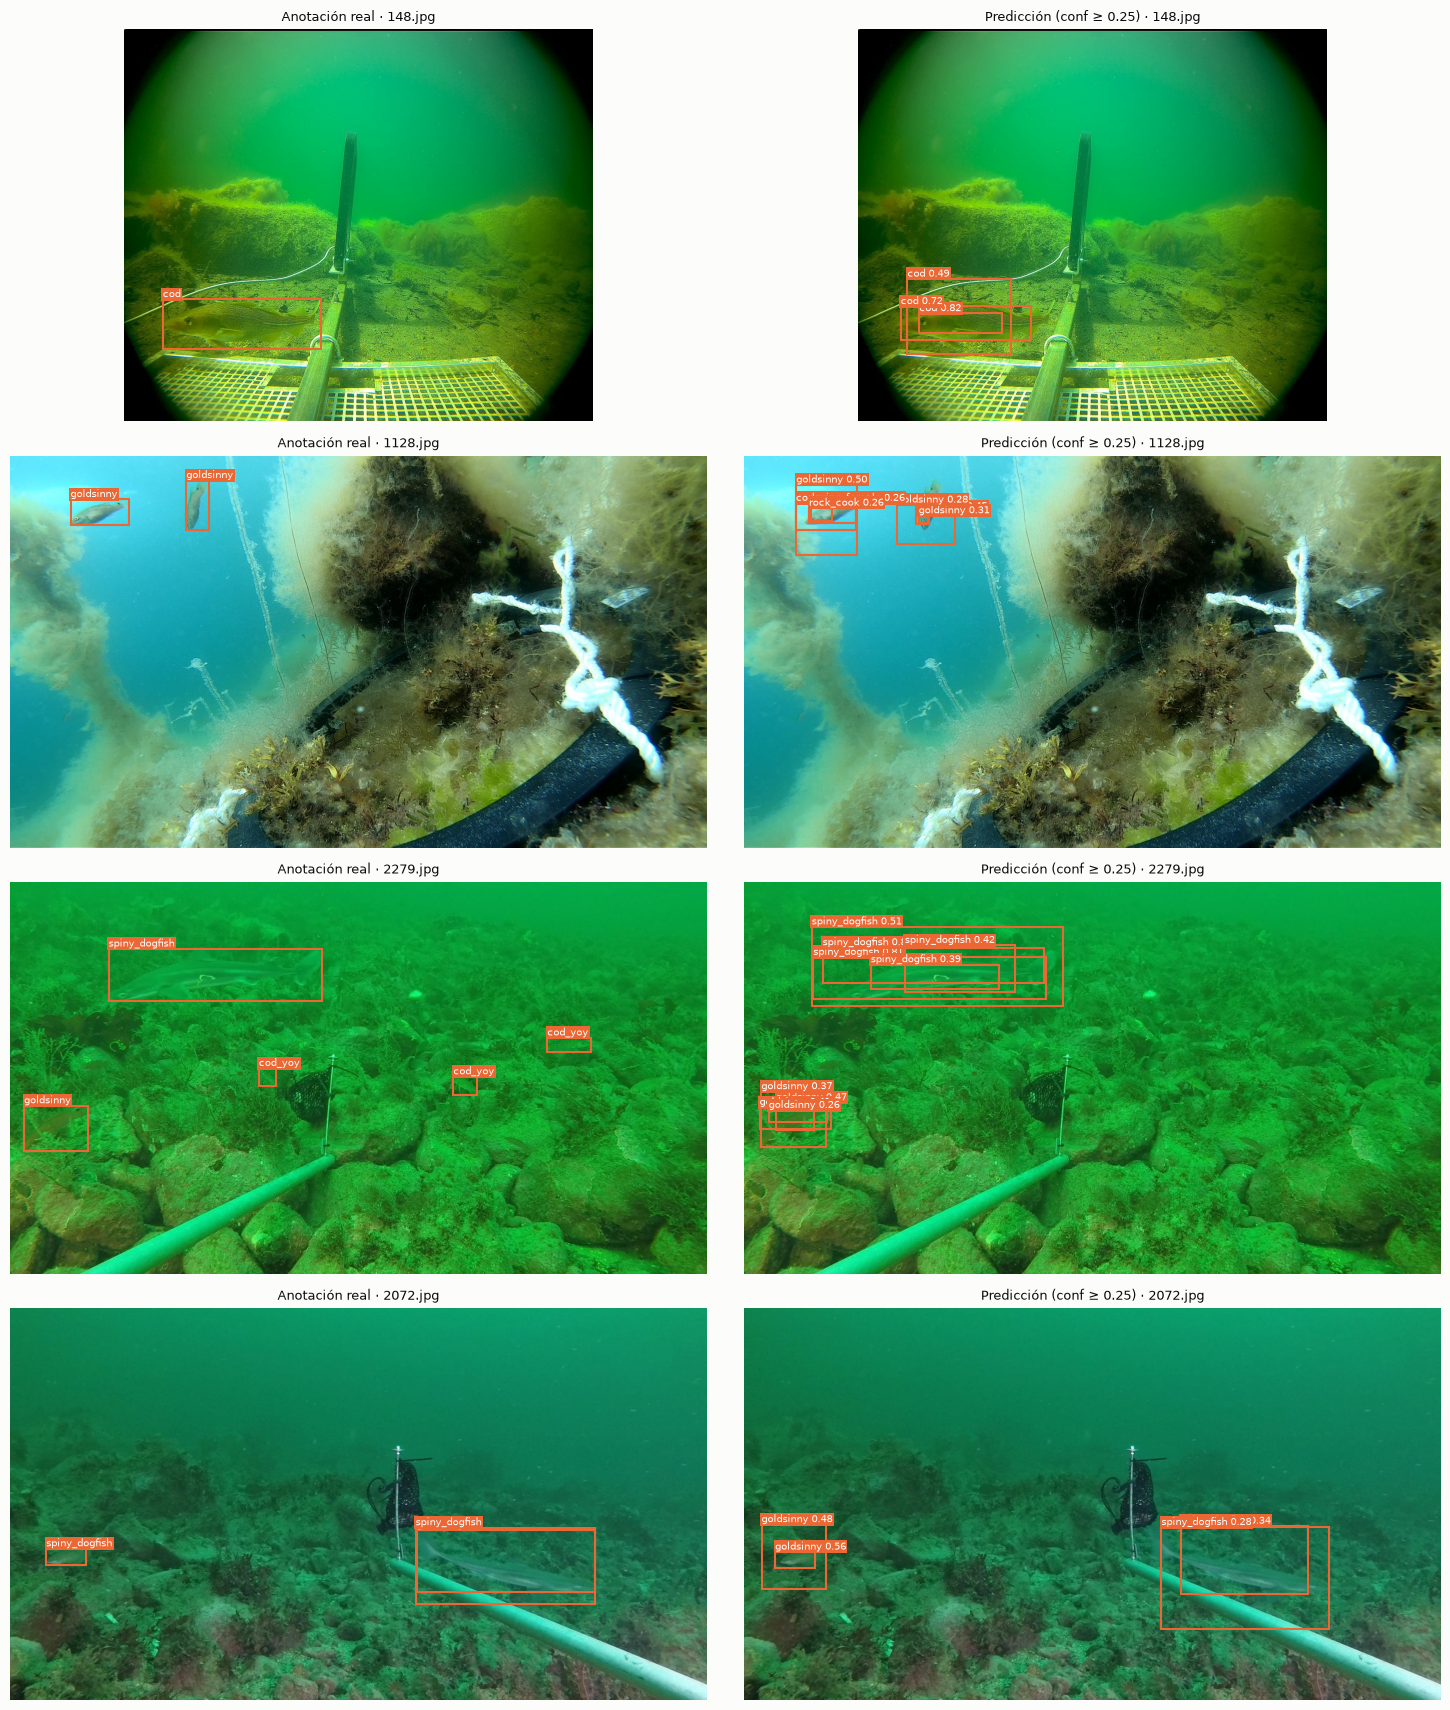

In [34]:
ejemplos = random.Random(SEMILLA).sample(rutas_test, N_EJEMPLOS)
reales_test = cargar_cajas_reales(DIR_DATASET, "test", particion["test"])
pred_test = predicciones["test"]
fig, axes = plt.subplots(N_EJEMPLOS, 2, figsize=(15, 4.3 * N_EJEMPLOS))
for (ax_real, ax_pred), ruta in zip(axes, ejemplos):
    img = Image.open(ruta)
    dibujar_cajas(ax_real, img, reales_test[reales_test.id == ruta.stem], f"Anotación real · {ruta.name}")
    dibujar_cajas(ax_pred, img, pred_test[(pred_test.id == ruta.stem) & (pred_test.confianza >= UMBRAL_CONFIANZA)],
                  f"Predicción (conf ≥ {UMBRAL_CONFIANZA}) · {ruta.name}")
fig.tight_layout()
fig.savefig(DIR_RESULTADOS / "ejemplos_test.png", dpi=120, bbox_inches="tight")
plt.show()

## 15. Predicciones y resumen para la comparación

Se guardan en `resultados/cnn_propia/` con el mismo formato que YOLO: `predicciones_val.csv` y `predicciones_test.csv`, `historial.csv` (columnas comunes por época) y `resumen.json` / `resumen.csv`, con las mismas claves que el resumen de YOLO. En este resumen, la precisión, el recall y el F1 usan `UMBRAL_CONFIANZA`, mientras que en el de YOLO usan el umbral que maximiza el F1 (Ultralytics). Por eso `05_comparacion.ipynb` los recalcula para todos los modelos con el umbral común (D8).

In [35]:
for split in ("val", "test"):
    predicciones[split].to_csv(DIR_RESULTADOS / f"predicciones_{split}.csv", index=False)
COLUMNAS_HISTORIAL = ["epoca", "tiempo_s", "perdida_train", "perdida_val", "val_mAP50", "val_mAP50_95"]
historial[COLUMNAS_HISTORIAL].to_csv(DIR_RESULTADOS / "historial.csv", index=False)

resumen = {
    "modelo": "CNN propia",
    "huella_particion": huella,
    "epocas_ejecutadas": int(historial.epoca.max()),
    "mejor_epoca": mejor_epoca,
    "tiempo_entrenamiento_min": info_entrenamiento["tiempo_entrenamiento_s"] / 60,
    "tiempo_por_epoca_s": tiempo_por_epoca_s,
    "memoria_gpu_max_GB": info_entrenamiento["memoria_gpu_max_GB"],
    **{f"test_{k}": metricas["test"][k] for k in CLAVES_METRICAS},
    **{f"val_{k}": metricas["val"][k] for k in CLAVES_METRICAS},
    **eficiencia,
}
(DIR_RESULTADOS / "resumen.json").write_text(json.dumps(resumen, indent=2, ensure_ascii=False), encoding="utf-8")
pd.Series(resumen).to_frame("valor").to_csv(DIR_RESULTADOS / "resumen.csv")
pd.Series(resumen).to_frame("valor")

,valor
modelo,CNN propia
huella_particion,84ea7ae5b688
epocas_ejecutadas,65
mejor_epoca,40
tiempo_entrenamiento_min,80.105
tiempo_por_epoca_s,73.943324
memoria_gpu_max_GB,3.27
test_precision,0.075233
test_recall,0.129451
test_F1,0.095162


## 16. ✍️ Justificación de las decisiones (completar por el grupo)

> La tarea pide justificar estas decisiones con argumentos propios del grupo; el uso de IA generativa para diseñar la solución o analizar resultados está prohibido.

- **Arquitectura** (bloques, filtros, grilla de 20 × 20, candidatas por celda):
- **Cambios de diseño de D2** (resultado de la prueba de sobreajuste):
- **Resolución de entrada y letterbox**:
- **Asignación y función de pérdida** (pesos de caja, clase y fondo):
- **Optimizador, tasa de aprendizaje y tamaño de lote**:
- **Número de épocas y parada temprana**:
- **Regularización** (L2, aumento de datos, parada temprana):
- **Aumento de datos**:
- **Desbalance de clases**:

## 17. ✍️ Análisis de resultados (completar por el grupo)

-

## ✍️ Declaración de uso de IA generativa

> Completar según lo que pide la tarea (herramienta y propósito específico).